# 02 - OpenCV : la boite a recettes du pretraitement

Ce notebook n'utilise QUE OpenCV, numpy et matplotlib : il se copie seul sur n'importe quel poste,
sans la toolbox. Une cinquantaine de recettes en 17 familles ; pour chacune : a quoi elle sert en
inspection, les parametres qui comptent et comment les regler, le piege classique, puis le code
et son effet sur une image reelle (bande d'acier NEU, tuiles magnetiques, bouteille MVTec).

Prerequis : `pip install opencv-python numpy matplotlib`. Donnees de la toolbox :
`python tools/get_data/get_neu_cls.py` (et `get_neu_det.py`, `get_magnetic_tile.py`,
`get_mvtec_bottle.py`) ; ou ses propres images : changer les chemins de la cellule REGLAGES.
Duree : moins de 2 minutes sur CPU.

**Dans le fil** : ce notebook approfondit l'etape 5 (Pretraiter). La famille 1 (lecture) sert aussi a
l'etape 2 (Importer et explorer), la famille 17 (tuiles) a l'etape 13 (Predire sur une grande image).
Le fil des 13 etapes, le meme que dans le cours : `ETAPES.md`, a la racine de la toolbox.

| # | famille | # | famille |
|---|---|---|---|
| 1 | lecture, ecriture, conventions | 10 | contours et mesures en mm |
| 2 | espaces de couleur | 11 | composantes connexes |
| 3 | geometrie | 12 | bords et gradients |
| 4 | histogramme et contraste | 13 | Hough (lignes, cercles) |
| 5 | illumination (shading) | 14 | frequences et texture |
| 6 | debruitage | 15 | correspondance et alignement |
| 7 | nettete et flou | 16 | segmentation classique |
| 8 | seuillage | 17 | tuiles et dessin d'annotations |
| 9 | morphologie | 18-19 | aide-memoire, chaine complete |

In [1]:
import time  # time : chronometre (mesurer la duree d'une operation)
import xml.etree.ElementTree as ET  # ElementTree : lecture de fichiers XML (annotations VOC des boites, section 17)
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images (toutes les recettes de ce notebook)
import matplotlib.pyplot as plt  # matplotlib : affichage des images et des courbes
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)

try:  # figures en JPEG dans le notebook (fichier .ipynb plus leger) ; sans effet hors Jupyter
    from IPython import get_ipython  # get_ipython : renvoie le noyau Jupyter en cours, ou None hors Jupyter

    if get_ipython() is not None:  # si on est bien dans Jupyter
        # equivaut a la commande magique %config : figures enregistrees en JPEG
        get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
except ImportError:  # si IPython n'est pas installe (script lance hors Jupyter)
    pass  # on ne fait rien
# reglages par defaut des figures : 80 points par pouce, petites polices
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 9, "font.size": 8})

# ---------------- REGLAGES : remplacer par ses propres images ----------------
DATA = Path("data/raw")  # dossier des donnees brutes telechargees
SCRATCH = DATA / "neu_cls_flat/scratches/Sc_10.bmp"  # rayures claires sur bande d'acier
SCRATCH_H = DATA / "neu_cls_flat/scratches/Sc_100.bmp"  # rayure horizontale + degrade d'eclairage
PATCHES = DATA / "neu_cls_flat/patches/Pa_100.bmp"  # plaques sombres
ROLLED = DATA / "neu_cls_flat/rolled/RS_10.bmp"  # calamine incrustee, faible contraste
CRAZING = DATA / "neu_cls_flat/crazing/Cr_1.bmp"  # texture craquelee
CRAZING_2 = DATA / "neu_cls_flat/crazing/Cr_10.bmp"  # une autre image de craquelures
ROLLED_2 = DATA / "neu_cls_flat/rolled/RS_1.bmp"  # une autre image de calamine
TILE_CRACK = DATA / "magnetic_tile/MT_Crack/Imgs/exp1_num_249594.jpg"  # fissure ; masque = meme nom en .png
TILE_HOLE = DATA / "magnetic_tile/MT_Blowhole/Imgs/exp1_num_317483.jpg"  # trou (blowhole)
TILE_FREE = DATA / "magnetic_tile/MT_Free/Imgs/exp0_num_743.jpg"  # tuile saine
BOTTLE_GOOD = DATA / "mvtec_bottle/train/good/000.png"  # bouteille MVTec sans defaut (vue de dessus, couleur)
BOTTLE_BAD = DATA / "mvtec_bottle/test/broken_large/000.png"  # bouteille au goulot casse
DET_IMAGE = DATA / "neu_det/IMAGES/inclusion_10.jpg"  # image + annotation VOC (boites)
DET_XML = DATA / "neu_det/ANNOTATIONS/inclusion_10.xml"  # fichier XML (format Pascal VOC) avec les boites de l'image ci-dessus
MM_PER_PX = 0.05  # echelle de la camera (mm par pixel) : a mesurer sur une mire (section 10)
OUT = Path("outputs/notebooks/02_opencv_pretraitements")  # dossier des sorties de ce notebook
# -----------------------------------------------------------------------------
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier (et ses parents) ; pas d'erreur s'il existe deja
rng = np.random.default_rng(0)  # generateur de hasard numpy, graine 0 : bruit simule identique a chaque execution
# versions installees (le comportement d'OpenCV varie un peu d'une version a l'autre)
print("OpenCV", cv2.__version__, "| numpy", np.__version__)

OpenCV 5.0.0 | numpy 2.4.6


Trois petits outils pour tout le notebook : `read_image` (lecture robuste), `write_image` et
`grid` (affichage). Matplotlib attend du RGB et etire les images grises sur leur min-max si on
ne fixe pas `vmin=0, vmax=255` : sans cela, une image sombre parait normale et on ne voit pas
l'effet d'une correction de contraste. `grid` fixe donc l'echelle des images `uint8`.

In [2]:
# lit une image (flags = mode de lecture) ; renvoie le tableau numpy tel qu'OpenCV le donne (couleur en BGR)
def read_image(path, flags=cv2.IMREAD_UNCHANGED):
    """Lit une image, y compris un chemin Windows avec accents (cv2.imread echoue dessus) et le 16 bits.

    IMREAD_UNCHANGED garde la profondeur (uint16) et les canaux ; IMREAD_GRAYSCALE donne du gris
    8 bits ; IMREAD_COLOR du BGR 8 bits.
    """
    data = np.fromfile(str(path), dtype=np.uint8)  # lit les octets bruts du fichier (accepte les chemins avec accents)
    image = cv2.imdecode(data, flags)  # cv2.imdecode(octets, mode) : decode les octets en image
    if image is None:  # None = le fichier n'est pas une image lisible
        raise FileNotFoundError(f"illisible : {path}")  # on arrete tout de suite avec un message clair
    return image  # renvoie l'image


def write_image(path, image, params=()):  # ecrit une image ; params = options d'encodage (ex. qualite JPEG) ; ne renvoie rien
    """Ecrit une image (chemin avec accents compris) ; l'extension choisit le format."""
    # cv2.imencode(extension, image, options) : encode en memoire ; ok = False si echec
    ok, buffer = cv2.imencode(Path(path).suffix, image, list(params))
    if not ok:  # si l'encodage a echoue
        raise ValueError(f"encodage impossible : {path}")  # on arrete avec un message clair
    buffer.tofile(str(path))  # ecrit les octets dans le fichier (marche avec les accents, contrairement a cv2.imwrite)


def to_rgb(image):  # prepare une image OpenCV pour matplotlib ; renvoie un tableau uint8 (RGB ou gris)
    """Image OpenCV -> affichable : BGR -> RGB ; masque 0/1 -> 0/255 ; autre type etire min-max."""
    im = np.asarray(image)  # s'assure d'avoir un tableau numpy
    if im.dtype == bool or (im.dtype == np.uint8 and im.max() == 1):  # si c'est un masque (booleens, ou uint8 qui ne vaut que 0 et 1)
        im = im.astype(np.uint8) * 255  # 0 / 1 -> 0 / 255 pour qu'il soit visible
    if im.dtype != np.uint8:  # si autre type (16 bits, float, valeurs negatives...)
        im = im.astype(np.float32)  # calcul en float32
        lo, hi = float(im.min()), float(im.max())  # plus petite et plus grande valeur
        # etirement lineaire de [lo, hi] vers [0, 255] (max evite une division par 0)
        im = ((im - lo) / max(hi - lo, 1e-6) * 255).astype(np.uint8)
    if im.ndim == 3 and im.shape[2] == 3:  # si image couleur (3 canaux)
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)  # BGR (OpenCV) -> RGB (matplotlib)
    return im  # image prete a afficher


def grid(images, titles=None, ncols=4, size=2.6, cmap="gray"):  # affiche une liste d'images en grille, avec titres ; ne renvoie rien
    """Affiche des images (BGR ou gris, tout type) cote a cote, a l'echelle 0-255 pour l'uint8."""
    ncols = min(ncols, len(images))  # pas plus de colonnes que d'images
    nrows = (len(images) + ncols - 1) // ncols  # nombre de lignes : division arrondie au-dessus
    # grille de cases ; squeeze=False : axes est toujours un tableau 2D
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():  # pour chaque case (ravel aplatit le tableau 2D)
        ax.axis("off")  # pas d'axes gradues autour des images
    for i, image in enumerate(images):  # pour chaque image, avec son numero i
        ax = axes.ravel()[i]  # la case numero i
        # dessine l'image ; vmin / vmax fixent l'echelle 0-255 (pas d'etirement automatique)
        ax.imshow(to_rgb(image), cmap=cmap, vmin=0, vmax=255)
        if titles:  # si des titres sont fournis
            ax.set_title(titles[i])  # titre de la case
    plt.tight_layout()  # resserre les marges
    plt.show()  # affiche la figure
    plt.close(fig)  # libere la memoire de la figure


def mask_of(path):  # lit le masque .png d'une image Magnetic Tile ; renvoie un masque uint8 0 / 255
    """Masque de verite terrain Magnetic Tile : meme nom que l'image, en .png (0 / 255)."""
    # with_suffix : meme nom en .png ; > 127 binarise ; x 255 donne 0 / 255
    return (read_image(Path(path).with_suffix(".png"), cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8) * 255

## 1. Lecture, ecriture et conventions

**Chemins avec accents (Windows)** : `cv2.imread` renvoie `None` SANS erreur sur un chemin non
ASCII sous Windows. `cv2.imdecode(np.fromfile(...))` lit les octets avec numpy puis decode : cela
marche partout. Toujours tester `is None` (ou passer par `read_image`, qui leve une erreur).

**Profondeur** : par defaut `imread` convertit en couleur 8 bits. Une camera industrielle 10, 12
ou 16 bits perd alors sa dynamique : lire avec `IMREAD_UNCHANGED` et verifier `dtype`.

In [3]:
tile = read_image(TILE_CRACK, cv2.IMREAD_GRAYSCALE)  # tuile magnetique lue en gris 8 bits
# simulation d'une camera 12 bits stockee en 16 bits (valeurs 0..4095) avec un decalage de noir
tile16 = (tile.astype(np.uint16) * 12 + 300).clip(0, 4095).astype(np.uint16)
path16 = OUT / "bobine_n\u00b012_\u00e9chantillon_16bits.png"  # nom avec accents : test des chemins
write_image(path16, tile16)  # ecrit en PNG 16 bits
for flags, name in [  # pour chaque mode de lecture, avec son nom
    (cv2.IMREAD_UNCHANGED, "IMREAD_UNCHANGED"),  # tel que stocke : 16 bits, 1 canal
    (cv2.IMREAD_GRAYSCALE, "IMREAD_GRAYSCALE"),  # converti en gris 8 bits
    (cv2.IMREAD_COLOR, "IMREAD_COLOR"),  # converti en couleur BGR 8 bits (3 canaux)
]:
    im = read_image(path16, flags)  # relit le fichier 16 bits dans ce mode
    # forme, type et plage : seul UNCHANGED garde les vraies valeurs (300-3360)
    print(f"{name:17s} shape={str(im.shape):14s} dtype={str(im.dtype):7s} min={im.min():5d} max={im.max():5d}")

IMREAD_UNCHANGED  shape=(264, 219)     dtype=uint16  min=  408 max= 2628
IMREAD_GRAYSCALE  shape=(264, 219)     dtype=uint8   min=    1 max=   10
IMREAD_COLOR      shape=(264, 219, 3)  dtype=uint8   min=    1 max=   10


**16 bits -> 8 bits** : diviser par 256 ecrase une image 12 bits dans 0-15 (noire) ; le min-max
depend d'un seul pixel chaud ; les percentiles (0,5 % - 99,5 %) sont robustes. En production les
bornes doivent etre FIXES (mesurees sur le jeu d'entrainement ou donnees par le capteur) : des
bornes recalculees par image changent le contraste d'une image a l'autre et peuvent effacer un
defaut qui occupe une grande partie de l'image.

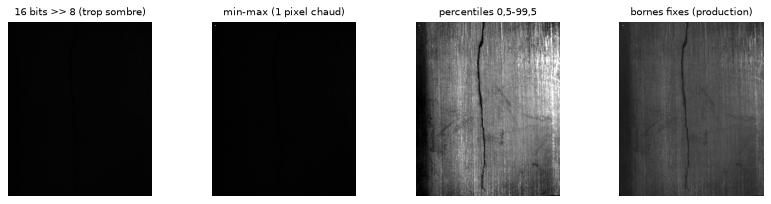

In [4]:
def to_8bit(image, low=0.5, high=99.5, bounds=None):  # conversion lineaire vers uint8 0-255 ; renvoie l'image 8 bits
    """Conversion lineaire vers 0-255 ; bounds=(lo, hi) fixes, sinon percentiles de l'image."""
    # bornes fixes si donnees, sinon percentiles low et high de l'image
    lo, hi = bounds if bounds is not None else np.percentile(image, (low, high))
    out = (image.astype(np.float32) - lo) * (255.0 / max(hi - lo, 1e-6))  # decale de lo puis met a l'echelle : lo -> 0, hi -> 255
    return np.clip(out, 0, 255).astype(np.uint8)  # coupe sous 0 et au-dessus de 255, puis passe en uint8


im16 = read_image(path16)  # relit l'image 16 bits (IMREAD_UNCHANGED par defaut)
im16_hot = im16.copy()  # copie independante, qu'on va abimer
im16_hot[5, 5] = 65535  # un seul pixel chaud (defaut de capteur)
naive = (im16 >> 8).astype(np.uint8)  # >> 8 : decalage de 8 bits = division par 256 ; 12 bits utiles -> valeurs 0-15, presque noir
# cv2.normalize NORM_MINMAX : min -> 0, max -> 255 ; CV_8U = sortie uint8 ; None = nouvelle image
minmax = cv2.normalize(im16_hot, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)
robust = to_8bit(im16_hot)  # percentiles 0,5 - 99,5 : le pixel chaud est ignore
fixed = to_8bit(im16_hot, bounds=(300, 3360))  # bornes fixes du capteur
grid(  # les quatre conversions cote a cote
    [naive, minmax, robust, fixed],  # images
    ["16 bits >> 8 (trop sombre)", "min-max (1 pixel chaud)", "percentiles 0,5-99,5", "bornes fixes (production)"],  # titres
    ncols=4,  # 4 images par ligne
)

**Conventions qui piegent** :
- une image est un tableau numpy `(hauteur, largeur[, canaux])` : on indexe `image[ligne, colonne]`,
  soit `image[y, x]` ; les fonctions OpenCV prennent des points `(x, y)` et des tailles
  `(largeur, hauteur)` (`cv2.resize(image, (w, h))`) ;
- la couleur est en **BGR** ; matplotlib, PIL et torchvision attendent du RGB ;
- un decoupage `image[y0:y1, x0:x1]` est une VUE : la modifier modifie l'image d'origine
  (`.copy()` pour une copie independante) ;
- `uint8` deborde en silence avec numpy (200 + 100 = 44) mais sature avec OpenCV (`cv2.add` -> 255) :
  calculer en `float32`, puis revenir en `uint8` avec `np.clip`.

shape (h, w, c) = (900, 900, 3) | pixel au point x=100, y=50 : [255 255 255] (ordre B, G, R)
apres roi[:] = 0, le pixel (110, 110) de l'image vaut [0 0 0] -> la vue a modifie l'original
numpy 200 + 100 = 44 | cv2.add = 255 | float puis clip = 255


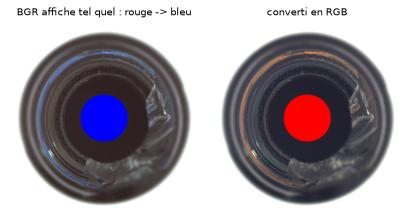

In [5]:
bottle = read_image(BOTTLE_BAD)  # bouteille lue telle quelle : couleur BGR, uint8
# attention : on indexe [y, x] = [ligne, colonne]
print("shape (h, w, c) =", bottle.shape, "| pixel au point x=100, y=50 :", bottle[50, 100], "(ordre B, G, R)")
roi = bottle[100:120, 100:120]  # decoupe 20 x 20 pixels : c'est une VUE (memes donnees en memoire), pas une copie
roi[:] = 0  # met a 0 tous les pixels de la vue
# le pixel (110, 110) de l'image d'origine est devenu noir lui aussi
print("apres roi[:] = 0, le pixel (110, 110) de l'image vaut", bottle[110, 110], "-> la vue a modifie l'original")
bottle = read_image(BOTTLE_BAD)  # on relit l'image intacte
a, b = np.array([[200]], np.uint8), np.array([[100]], np.uint8)  # deux tableaux 1 x 1 en uint8 (entiers 0-255)
print(  # compare trois facons d'additionner 200 + 100 en uint8
    "numpy 200 + 100 =",  # texte
    (a + b)[0, 0],  # numpy deborde : 300 - 256 = 44
    "| cv2.add =",  # texte
    cv2.add(a, b)[0, 0],  # OpenCV sature : 255
    "| float puis clip =",  # texte
    np.clip(a.astype(np.float32) + b, 0, 255).astype(np.uint8)[0, 0],  # calcul en float32, coupe a 255, retour en uint8 : 255
)
painted = bottle.copy()  # copie sur laquelle on dessine
# cv2.circle(image, centre (x, y), rayon, couleur BGR, epaisseur ; -1 = disque plein) : rouge = (0, 0, 255)
cv2.circle(painted, (450, 450), 110, (0, 0, 255), -1)
fig, axes = plt.subplots(1, 2, figsize=(5.2, 2.7))  # deux cases cote a cote ; figsize en pouces
axes[0].imshow(painted)  # BGR affiche sans conversion : matplotlib le lit comme du RGB
axes[0].set_title("BGR affiche tel quel : rouge -> bleu")  # titre de la case
axes[1].imshow(cv2.cvtColor(painted, cv2.COLOR_BGR2RGB))  # meme image convertie BGR -> RGB : couleurs justes
axes[1].set_title("converti en RGB")  # titre de la case
for ax in axes:  # pour chaque case
    ax.axis("off")  # pas d'axes gradues
plt.tight_layout()  # resserre les marges
plt.show()  # affiche la figure

## 2. Espaces de couleur

- **gris** (`COLOR_BGR2GRAY`, 0,299 R + 0,587 G + 0,114 B) : la plupart des defauts d'acier sont
  des variations de luminance ; un canal, c'est trois fois moins de calcul ;
- **HSV** : teinte H, saturation S, valeur V ; pour isoler une couleur (marquage peinture, rouille)
  independamment de l'eclairage, qui change surtout V ;
- **Lab** : L = luminance perceptuelle, a et b = couleur ; pour corriger le contraste sans toucher la
  couleur (CLAHE sur L seul) ou mesurer un ecart de teinte (Delta E = distance dans Lab).

Piege : en 8 bits, H va de 0 a 179 (360 degres / 2) et le rouge est aux DEUX bouts (0-10 et 170-179).

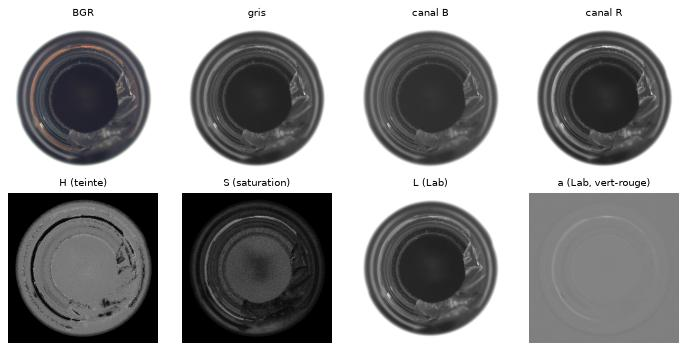

In [6]:
gray = cv2.cvtColor(bottle, cv2.COLOR_BGR2GRAY)  # BGR -> gris : 0,299 R + 0,587 G + 0,114 B
hsv = cv2.cvtColor(bottle, cv2.COLOR_BGR2HSV)  # BGR -> HSV : teinte, saturation, valeur
lab = cv2.cvtColor(bottle, cv2.COLOR_BGR2LAB)  # BGR -> Lab : L luminance, a vert-rouge, b bleu-jaune
blue, green, red = cv2.split(bottle)  # cv2.split : separe les 3 canaux en 3 images grises
grid(  # les representations cote a cote
    # hsv[..., 0] : canal 0 (H) de chaque pixel ; "..." = tous les axes precedents
    [bottle, gray, blue, red, hsv[..., 0], hsv[..., 1], lab[..., 0], lab[..., 1]],
    ["BGR", "gris", "canal B", "canal R", "H (teinte)", "S (saturation)", "L (Lab)", "a (Lab, vert-rouge)"],  # titres
    ncols=4,  # 4 images par ligne
    size=2.2,  # taille d'une case en pouces
)

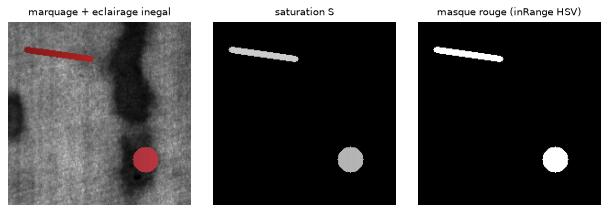

In [7]:
# cas industriel : reperer un marquage peinture rouge sur une bande, quel que soit l'eclairage
# image grise d'acier convertie en BGR 3 canaux (pour y dessiner en couleur)
steel = cv2.cvtColor(read_image(PATCHES, cv2.IMREAD_GRAYSCALE), cv2.COLOR_GRAY2BGR)
marked = steel.copy()  # copie a marquer
cv2.line(marked, (20, 30), (90, 40), (40, 40, 200), 6)  # cv2.line(image, point 1, point 2, couleur BGR, epaisseur 6) : trait rouge
cv2.circle(marked, (150, 150), 14, (60, 50, 170), -1)  # pastille rouge plus sombre, teinte vers 175
ramp = np.linspace(0.6, 1.2, marked.shape[1])[None, :, None]  # eclairage inegal de gauche a droite
marked = np.clip(marked.astype(np.float32) * ramp, 0, 255).astype(np.uint8)  # applique l'eclairage en float, coupe a 0-255, retour en uint8
hsv_m = cv2.cvtColor(marked, cv2.COLOR_BGR2HSV)  # passage en HSV : la teinte H change peu avec l'eclairage
# cv2.inRange(image, bas, haut) : 255 si chaque canal est entre ses bornes ; rouge = H 0-10 OU 170-179 (| = ou)
red_mask = cv2.inRange(hsv_m, (0, 80, 40), (10, 255, 255)) | cv2.inRange(hsv_m, (170, 80, 40), (179, 255, 255))
# image marquee, saturation, masque obtenu
grid([marked, hsv_m[..., 1], red_mask], ["marquage + eclairage inegal", "saturation S", "masque rouge (inRange HSV)"], ncols=3)

## 3. Geometrie

### Redimensionner : le choix de l'interpolation compte
- **reduire** : `INTER_AREA` (moyenne des pixels couverts) ; `INTER_NEAREST` et `INTER_LINEAR`
  sautent des pixels : crenelage (moire) sur les textures fines, rayure d'un pixel effacee ;
- **agrandir** : `INTER_LINEAR` (rapide) ou `INTER_CUBIC` (plus net) ;
- **masques et cartes d'etiquettes** : TOUJOURS `INTER_NEAREST` (sinon des valeurs intermediaires,
  donc de fausses classes, apparaissent sur les bords).

Piege : `cv2.resize(image, (largeur, hauteur))`, pas `(h, w)`.

valeurs du masque reduit : NEAREST [  0 255] | LINEAR 11 valeurs differentes


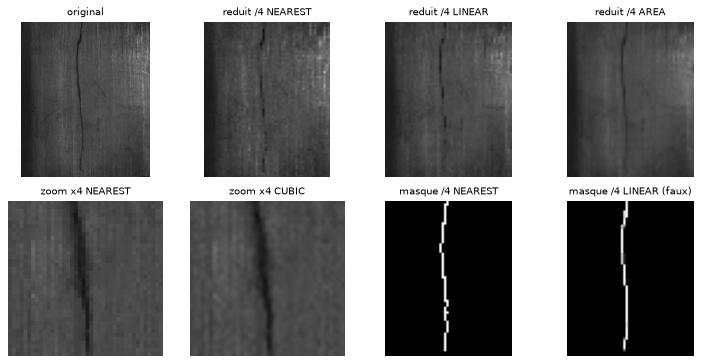

In [8]:
tile = read_image(TILE_CRACK, cv2.IMREAD_GRAYSCALE)  # tuile fissuree en gris
crack_mask = mask_of(TILE_CRACK)  # son masque de verite terrain
ys, xs = np.nonzero(crack_mask)  # coordonnees (lignes, colonnes) des pixels non nuls du masque
cy, cx = int(np.median(ys)), int(np.median(xs))  # centre approximatif de la fissure (mediane des coordonnees)
quarter = (tile.shape[1] // 4, tile.shape[0] // 4)  # taille au quart, au format OpenCV (largeur, hauteur)
small = {  # trois reductions au quart, une par interpolation
    # cv2.resize(image, (largeur, hauteur), interpolation = methode de calcul des nouveaux pixels)
    name: cv2.resize(tile, quarter, interpolation=flag)
    for name, flag in [("NEAREST", cv2.INTER_NEAREST), ("LINEAR", cv2.INTER_LINEAR), ("AREA", cv2.INTER_AREA)]  # pour chaque methode
}
# recadrage 40 x 40 autour de la fissure (max(..., 0) evite un indice negatif)
crop = tile[max(cy - 20, 0) : cy + 20, max(cx - 20, 0) : cx + 20]
# zoom x4 : dsize=None, la taille vient des facteurs fx et fy
big = [cv2.resize(crop, None, fx=4, fy=4, interpolation=f) for f in (cv2.INTER_NEAREST, cv2.INTER_CUBIC)]
# masque reduit au quart en NEAREST et en LINEAR
mask_small = [cv2.resize(crack_mask, quarter, interpolation=f) for f in (cv2.INTER_NEAREST, cv2.INTER_LINEAR)]
# NEAREST garde 0 et 255 ; LINEAR cree des valeurs intermediaires (fausses classes)
print("valeurs du masque reduit : NEAREST", np.unique(mask_small[0])[:6], "| LINEAR", len(np.unique(mask_small[1])), "valeurs differentes")
grid(  # tout cote a cote
    [tile] + list(small.values()) + big + mask_small,  # original, 3 reductions, 2 zooms, 2 masques
    # titres dans le meme ordre
    ["original"] + [f"reduit /4 {k}" for k in small] + ["zoom x4 NEAREST", "zoom x4 CUBIC", "masque /4 NEAREST", "masque /4 LINEAR (faux)"],
    ncols=4,  # 4 images par ligne
    size=2.3,  # taille d'une case en pouces
)

### Letterbox : un carre sans deformer
Les detecteurs (YOLO...) prennent une entree carree. Etirer (`resize` direct) deforme les defauts :
un trou rond devient ovale. Le letterbox met a l'echelle en gardant les proportions puis complete
par des bandes ; il faut garder `ratio, dx, dy` pour ramener les boites aux coordonnees d'origine.

image 458x240 -> ratio 0.699, dx=0, dy=76


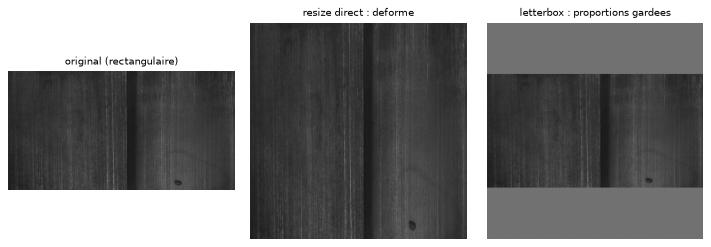

In [9]:
def letterbox(image, size=320, pad=114):  # met l'image dans un carre sans la deformer ; renvoie (image, ratio, dx, dy)
    """Image dans un carre size x size sans deformation ; renvoie (image, ratio, dx, dy).

    Retour aux coordonnees d'origine : x_orig = (x - dx) / ratio, y_orig = (y - dy) / ratio.
    """
    h, w = image.shape[:2]  # hauteur et largeur (shape[:2] marche en gris comme en couleur)
    ratio = size / max(h, w)  # facteur d'echelle : le plus grand cote devient size
    nh, nw = round(h * ratio), round(w * ratio)  # nouvelles hauteur et largeur, proportions gardees
    # mise a l'echelle : AREA pour reduire, LINEAR pour agrandir
    resized = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_AREA if ratio < 1 else cv2.INTER_LINEAR)
    dy, dx = (size - nh) // 2, (size - nw) // 2  # marges en haut et a gauche pour centrer l'image
    # cv2.copyMakeBorder(image, haut, bas, gauche, droite, type, value) : bandes de valeur pad (114 = gris)
    out = cv2.copyMakeBorder(resized, dy, size - nh - dy, dx, size - nw - dx, cv2.BORDER_CONSTANT, value=(pad, pad, pad))
    return out, ratio, dx, dy  # l'image carree et de quoi revenir aux coordonnees d'origine


# image large : deux morceaux de tuiles colles cote a cote (hconcat exige la meme hauteur)
wide = cv2.hconcat([read_image(TILE_FREE, cv2.IMREAD_GRAYSCALE)[:240, :240], read_image(TILE_HOLE, cv2.IMREAD_GRAYSCALE)[:240, :218]])
boxed, ratio, dx, dy = letterbox(wide, 320)  # letterbox a 320 x 320
stretched = cv2.resize(wide, (320, 320), interpolation=cv2.INTER_AREA)  # resize direct a 320 x 320 : etire, donc deforme
# ratio et decalages a garder pour revenir aux coordonnees d'origine
print(f"image {wide.shape[1]}x{wide.shape[0]} -> ratio {ratio:.3f}, dx={dx}, dy={dy}")
# les trois versions cote a cote
grid([wide, stretched, boxed], ["original (rectangulaire)", "resize direct : deforme", "letterbox : proportions gardees"], ncols=3, size=3)

### Recadrer, tourner, retourner
- recadrage = decoupage numpy `image[y0:y1, x0:x1]` ;
- rotation quelconque : `getRotationMatrix2D(centre, angle, echelle)` + `warpAffine` ; agrandir le
  canevas pour ne pas couper les coins, et choisir le remplissage (`borderMode`) : des coins noirs
  sont une "texture" qu'un reseau peut apprendre ; `BORDER_REFLECT` les evite ;
- rotations de 90 degres et miroirs : `cv2.rotate`, `cv2.flip` (exacts, sans interpolation).

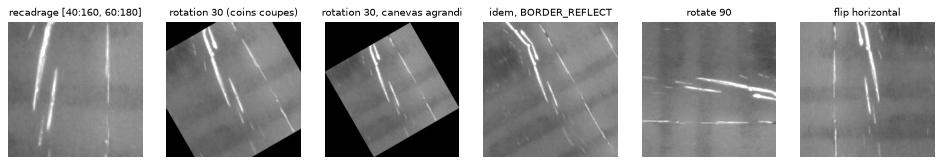

In [10]:
# tourne l'image d'un angle quelconque sans couper les coins ; renvoie l'image tournee
def rotate_full(image, angle, border=cv2.BORDER_CONSTANT):
    """Rotation de `angle` degres (sens trigonometrique) sur un canevas agrandi : rien n'est coupe."""
    h, w = image.shape[:2]  # hauteur et largeur
    # cv2.getRotationMatrix2D(centre, angle en degres, echelle) : matrice 2 x 3 de la rotation
    m = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(m[0, 0]), abs(m[0, 1])  # cosinus et sinus de l'angle, lus dans la matrice
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)  # taille du canevas qui contient toute l'image tournee
    m[0, 2] += nw / 2 - w / 2  # decale la translation de la matrice pour centrer l'image dans le nouveau canevas
    m[1, 2] += nh / 2 - h / 2  # meme recentrage en vertical
    # cv2.warpAffine(image, matrice, taille (l, h), interpolation, borderMode = remplissage hors image)
    return cv2.warpAffine(image, m, (nw, nh), flags=cv2.INTER_LINEAR, borderMode=border)


steel = read_image(SCRATCH, cv2.IMREAD_GRAYSCALE)  # image d'acier rayee, en gris
h, w = steel.shape  # hauteur et largeur
# rotation de 30 degres dans le meme cadre : les coins sortent et sont coupes
rot_cut = cv2.warpAffine(steel, cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1.0), (w, h))
grid(  # six variantes cote a cote
    [  # images
        steel[40:160, 60:180],  # recadrage : lignes 40 a 159, colonnes 60 a 179
        rot_cut,  # rotation simple
        rotate_full(steel, 30),  # rotation, canevas agrandi, coins noirs
        rotate_full(steel, 30, cv2.BORDER_REFLECT),  # BORDER_REFLECT : les coins sont remplis par un miroir de l'image
        cv2.rotate(steel, cv2.ROTATE_90_CLOCKWISE),  # rotation exacte de 90 degres dans le sens horaire
        cv2.flip(steel, 1),  # flip(image, 1) : miroir gauche-droite (0 = haut-bas, -1 = les deux)
    ],
    [  # titres
        "recadrage [40:160, 60:180]",  # titre 1
        "rotation 30 (coins coupes)",  # titre 2
        "rotation 30, canevas agrandi",  # titre 3
        "idem, BORDER_REFLECT",  # titre 4
        "rotate 90",  # titre 5
        "flip horizontal",  # titre 6
    ],
    ncols=6,  # 6 images sur une ligne
    size=2.0,  # taille d'une case en pouces
)

### Affine (3 points) et redressement de perspective (4 points)
Une camera inclinee voit une plaque rectangulaire en trapeze. Avec les 4 coins (cliques une fois a
l'installation, ou trouves par contours ou sur une mire), `getPerspectiveTransform` +
`warpPerspective` redressent l'image : une mesure en mm devient valable partout dans le champ.
L'affine (3 points) corrige rotation, echelle et cisaillement, pas la perspective.

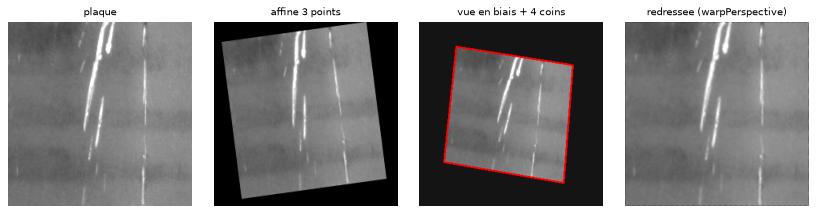

In [11]:
# 4 coins de l'image (x, y) : haut-gauche, haut-droit, bas-droit, bas-gauche ; float32 exige par OpenCV
src = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])
seen_corners = np.float32([[60, 40], [250, 70], [235, 262], [40, 228]])  # la plaque vue en biais
# cv2.getPerspectiveTransform(4 points, 4 points) : matrice 3 x 3 ; warpPerspective l'applique (300 x 300, fond 20)
seen = cv2.warpPerspective(steel, cv2.getPerspectiveTransform(src, seen_corners), (300, 300), borderValue=20)
rectified = cv2.warpPerspective(seen, cv2.getPerspectiveTransform(seen_corners, src), (w, h))  # coins vus -> rectangle reel
# cv2.getAffineTransform(3 points, 3 points) : matrice 2 x 3 ; warpAffine l'applique dans un cadre 230 x 230
affine = cv2.warpAffine(steel, cv2.getAffineTransform(src[:3], np.float32([[10, 25], [190, 0], [215, 195]])), (230, 230))
drawn = cv2.cvtColor(seen, cv2.COLOR_GRAY2BGR)  # copie couleur de la vue en biais, pour y dessiner en rouge
# cv2.polylines(image, [points entiers], ferme=True, couleur, epaisseur) : trace le quadrilatere
cv2.polylines(drawn, [seen_corners.astype(np.int32)], True, (0, 0, 255), 2)
# plaque, affine, vue en biais, redressee
grid([steel, affine, drawn, rectified], ["plaque", "affine 3 points", "vue en biais + 4 coins", "redressee (warpPerspective)"], ncols=4)

### Coordonnees polaires : derouler une piece ronde
Goulot, joint, roulement : en polaire (`warpPolar`), le cercle devient une bande ; un defaut sur le
pourtour se cherche comme sur une bande d'acier (profil, seuil par ligne). Le centre doit etre
precis (a quelques pixels) : le mesurer une fois, ou le trouver par Hough (section 13).

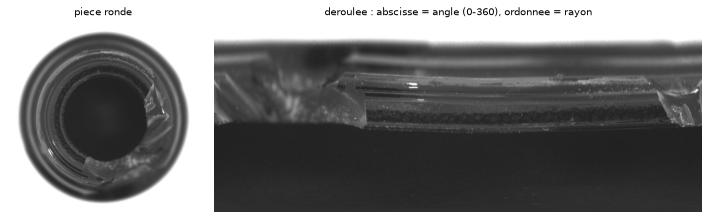

In [12]:
bottle_g = cv2.cvtColor(bottle, cv2.COLOR_BGR2GRAY)  # bouteille en gris
center = (bottle_g.shape[1] / 2, bottle_g.shape[0] / 2)  # centre de l'image (x, y), suppose au centre de la bouteille
radius = 0.5 * bottle_g.shape[0]  # rayon de deroulage : la moitie de la hauteur
# cv2.warpPolar(image, (largeur = rayon, hauteur = 720 angles), centre, rayon max, LINEAR) : lignes = angle, colonnes = rayon
polar = cv2.warpPolar(bottle_g, (int(radius), 720), center, radius, cv2.WARP_POLAR_LINEAR)
unrolled = cv2.rotate(polar, cv2.ROTATE_90_COUNTERCLOCKWISE)  # angle en abscisse, rayon vers le haut
# deux cases, la seconde 2,4 fois plus large (width_ratios)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), gridspec_kw={"width_ratios": [1, 2.4]})
axes[0].imshow(bottle_g, cmap="gray", vmin=0, vmax=255)  # affiche en gris sur l'echelle 0-255
axes[0].set_title("piece ronde")  # titre de la case
axes[1].imshow(unrolled, cmap="gray", vmin=0, vmax=255, aspect="auto")  # aspect="auto" : l'image remplit la case, quitte a etre etiree
axes[1].set_title("deroulee : abscisse = angle (0-360), ordonnee = rayon")  # titre de la case
for ax in axes:  # pour chaque case
    ax.axis("off")  # pas d'axes gradues
plt.tight_layout()  # resserre les marges
plt.show()  # affiche la figure

## 4. Histogramme et contraste
- **histogramme** (`cv2.calcHist`) : premier diagnostic (image sous-exposee, saturee, bimodale) ;
- **etirement par percentiles** : lineaire et previsible, garde l'ordre des niveaux ; le plus sur ;
- **egalisation globale** (`equalizeHist`) : forte, amplifie le bruit des zones uniformes ;
- **CLAHE** : egalisation locale par tuiles (`tileGridSize`, 8x8) avec une limite d'amplification
  (`clipLimit`, de 1 a 4) : fait ressortir les defauts faibles malgre un eclairage inegal ;
- **gamma** (par une table `LUT` de 256 valeurs calculee une fois) : gamma < 1 eclaircit les sombres.

Piege : une operation qui depend de l'image (egalisation, CLAHE, percentiles par image) change la
luminance absolue. Si le critere est "plus sombre que la normale", fixer les parametres sur le jeu
d'entrainement et les garder tels quels en production.

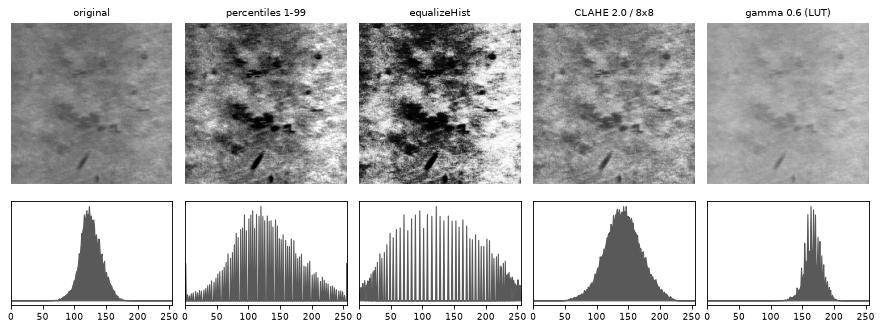

In [13]:
def stretch(image, low=1, high=99):  # etirement lineaire entre deux percentiles ; renvoie une image uint8
    lo, hi = np.percentile(image, (low, high))  # niveaux de gris sous lesquels se trouvent 1 % et 99 % des pixels
    # lo -> 0, hi -> 255, coupe au-dela, retour en uint8 (max(..., 1) evite une division par 0)
    return np.clip((image.astype(np.float32) - lo) * 255 / max(hi - lo, 1), 0, 255).astype(np.uint8)


def gamma_lut(gamma):  # table de correspondance (LUT) d'une correction gamma ; renvoie 256 valeurs uint8
    """Table de 256 valeurs : sortie = 255 * (entree / 255) ** gamma."""
    # pour chaque niveau 0-255, sa valeur apres correction gamma
    return np.clip(((np.arange(256) / 255.0) ** gamma) * 255, 0, 255).astype(np.uint8)


rolled = read_image(ROLLED, cv2.IMREAD_GRAYSCALE)  # image de calamine, faible contraste, en gris
# cv2.createCLAHE : egalisation locale ; clipLimit = limite d'amplification, tileGridSize = grille 8 x 8 tuiles
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
versions = {  # cinq versions de la meme image, par nom
    "original": rolled,  # l'image de depart
    "percentiles 1-99": stretch(rolled),  # etirement 1-99 %
    "equalizeHist": cv2.equalizeHist(rolled),  # cv2.equalizeHist : egalisation globale (histogramme rendu plat)
    "CLAHE 2.0 / 8x8": clahe.apply(rolled),  # CLAHE applique a l'image
    # cv2.LUT(image, table) : remplace chaque niveau par sa valeur dans la table (gamma 0,6 eclaircit)
    "gamma 0.6 (LUT)": cv2.LUT(rolled, gamma_lut(0.6)),
}
# 2 lignes x 5 colonnes : images en haut, histogrammes en bas (moins hauts)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.4), gridspec_kw={"height_ratios": [2.2, 1]})
for i, (name, im) in enumerate(versions.items()):  # pour chaque version, avec son numero de colonne i
    axes[0, i].imshow(im, cmap="gray", vmin=0, vmax=255)  # image sur l'echelle 0-255
    axes[0, i].set_title(name)  # titre de la case
    axes[0, i].axis("off")  # pas d'axes gradues
    # cv2.calcHist([images], [canal 0], pas de masque, 256 cases, plage [0, 256]) ; ravel : tableau 1D
    hist = cv2.calcHist([im], [0], None, [256], [0, 256]).ravel()
    axes[1, i].fill_between(np.arange(256), hist, color="0.35")  # histogramme dessine comme une aire grise ("0.35" = gris fonce)
    axes[1, i].set_xlim(0, 255)  # axe horizontal de 0 a 255
    axes[1, i].set_yticks([])  # pas de graduations verticales
plt.tight_layout()  # resserre les marges
plt.show()  # affiche la figure

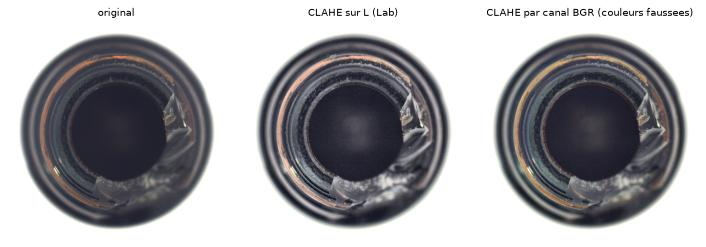

In [14]:
# image couleur : CLAHE sur la luminance L de Lab seulement (sinon les couleurs virent)
lab = cv2.cvtColor(bottle, cv2.COLOR_BGR2LAB)  # BGR -> Lab
# CLAHE (limite 3, tuiles 8 x 8) applique au seul canal L
lab[..., 0] = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(lab[..., 0])
bottle_clahe = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)  # retour Lab -> BGR
# contre-exemple : CLAHE sur B, G et R separement, puis cv2.merge recolle les canaux
per_channel = cv2.merge([cv2.createCLAHE(3.0, (8, 8)).apply(c) for c in cv2.split(bottle)])
# comparaison des trois versions
grid([bottle, bottle_clahe, per_channel], ["original", "CLAHE sur L (Lab)", "CLAHE par canal BGR (couleurs faussees)"], ncols=3, size=3)

## 5. Illumination : corriger le shading

C'est LE pretraitement de l'acier et des surfaces : l'eclairage n'est jamais uniforme (degrade,
vignetage, bandes de la camera lineaire). Un seuil fixe ou un modele voient alors "l'eclairage"
au lieu du defaut.

### Division par le fond flou
L'eclairage est multiplicatif (image = reflectance x eclairage) : on estime l'eclairage par un flou
tres large, puis on divise. Reglage de `sigma` : nettement plus grand que le plus gros defaut a
garder (sinon le defaut entre dans le fond : halo et defaut affaibli), plus petit que les variations
d'eclairage a supprimer. Point de depart : 3 a 5 fois la taille du defaut.

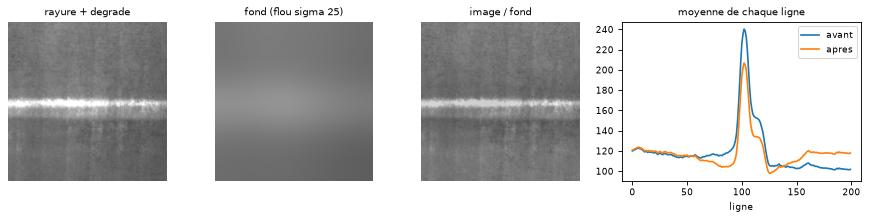

In [15]:
def flatten_division(image, sigma=25.0):  # corrige un eclairage multiplicatif ; renvoie (image corrigee uint8, fond estime)
    """Corrige un eclairage multiplicatif : image / fond flou, ramene a la moyenne d'origine."""
    img = image.astype(np.float32)  # calcul en float32 (pas de debordement)
    # cv2.GaussianBlur(image, (0, 0), sigma) : flou gaussien ; (0, 0) = taille du noyau deduite de sigma
    background = cv2.GaussianBlur(img, (0, 0), sigma)
    # divise par le fond (au moins 1, pour eviter / 0), puis remet la luminosite moyenne d'origine
    out = img / np.maximum(background, 1.0) * float(background.mean())
    return np.clip(out, 0, 255).astype(np.uint8), background  # image ramenee a 0-255 en uint8, et le fond


band = read_image(SCRATCH_H, cv2.IMREAD_GRAYSCALE)  # rayure horizontale + degrade d'eclairage
flat, background = flatten_division(band, sigma=25)  # correction avec un flou de sigma 25
# 4 cases, la derniere plus large pour la courbe
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
# pour les 3 premieres cases : image, fond, image corrigee
for ax, im, title in zip(axes[:3], [band, background, flat], ["rayure + degrade", "fond (flou sigma 25)", "image / fond"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)  # image sur l'echelle 0-255
    ax.set_title(title)  # titre de la case
    ax.axis("off")  # pas d'axes gradues
axes[3].plot(band.mean(axis=1), label="avant")  # moyenne de chaque ligne avant correction : montre le degrade
axes[3].plot(flat.mean(axis=1), label="apres")  # apres correction : courbe plate
axes[3].set_title("moyenne de chaque ligne")  # titre de la courbe
axes[3].set_xlabel("ligne")  # nom de l'axe horizontal
axes[3].legend()  # legende avant / apres
plt.tight_layout()  # resserre les marges
plt.show()  # affiche la figure

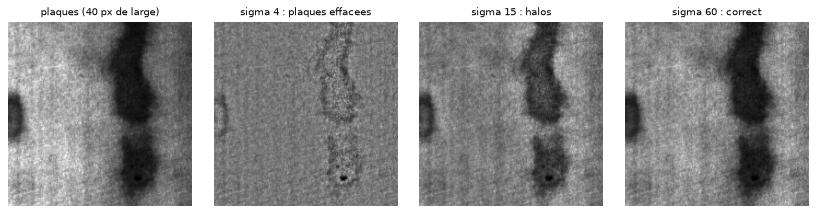

In [16]:
# le choix de sigma sur de grosses plaques sombres : trop petit, la plaque est "absorbee" par le fond
patches = read_image(PATCHES, cv2.IMREAD_GRAYSCALE)  # plaques sombres en gris
results = [flatten_division(patches, s)[0] for s in (4, 15, 60)]  # correction avec 3 sigmas ; [0] garde l'image (pas le fond)
# comparaison des 3 sigmas
grid([patches] + results, ["plaques (40 px de large)", "sigma 4 : plaques effacees", "sigma 15 : halos", "sigma 60 : correct"], ncols=4)

### Soustraction du fond, fond median, top-hat et black-hat
- **soustraction** (`image - fond + moyenne`) : pour un decalage additif (lumiere parasite) ;
- **fond median** (`medianBlur` large) : insensible aux petits defauts tres contrastes, que le flou
  gaussien etale ;
- **top-hat** (image - ouverture) : garde les details CLAIRS plus petits que l'element structurant ;
  **black-hat** (fermeture - image) : les details SOMBRES (trous, fissures). L'element doit etre
  plus grand que le defaut (ici 21 pixels). Le resultat est une carte "ecart au fond", prete a seuiller.

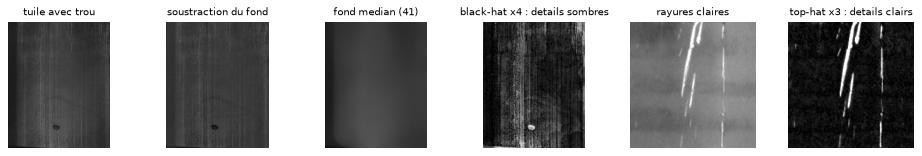

In [17]:
hole = read_image(TILE_HOLE, cv2.IMREAD_GRAYSCALE)  # tuile avec un trou, en gris
# cv2.getStructuringElement(forme, taille) : element structurant en disque de 21 x 21 pixels
ellipse21 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21))
blur_bg = cv2.GaussianBlur(hole.astype(np.float32), (0, 0), 20)  # fond = flou gaussien large (sigma 20), en float32
# soustraction : image - fond + moyenne du fond, ramenee en uint8
subtracted = np.clip(hole - blur_bg + blur_bg.mean(), 0, 255).astype(np.uint8)
median_bg = cv2.medianBlur(hole, 41)  # cv2.medianBlur(image, 41) : chaque pixel = mediane de sa fenetre 41 x 41 (taille impaire)
# cv2.morphologyEx(image, operation, element) ; BLACKHAT = fermeture - image : details sombres
blackhat = cv2.morphologyEx(hole, cv2.MORPH_BLACKHAT, ellipse21)
tophat = cv2.morphologyEx(steel, cv2.MORPH_TOPHAT, ellipse21)  # TOPHAT = image - ouverture : details clairs plus petits que l'element
grid(  # six images cote a cote
    # cv2.multiply(image, 4) : multiplie avec saturation a 255, pour rendre visibles des ecarts faibles
    [hole, subtracted, median_bg, cv2.multiply(blackhat, 4), steel, cv2.multiply(tophat, 3)],
    [  # titres
        "tuile avec trou",  # titre 1
        "soustraction du fond",  # titre 2
        "fond median (41)",  # titre 3
        "black-hat x4 : details sombres",  # titre 4
        "rayures claires",  # titre 5
        "top-hat x3 : details clairs",  # titre 6
    ],
    ncols=6,  # 6 images sur une ligne
    size=2.0,  # taille d'une case en pouces
)

### Flat field (image de reference) et profil de colonnes (camera lineaire)
- **flat field** : avec une image "blanche" (meme eclairage, surface uniforme ou diffuseur) et une
  image "noire" (objectif bouche), `(brute - noir) / (blanc - noir)` corrige exactement vignetage et
  gain de chaque pixel. A refaire quand l'eclairage ou l'optique changent ;
- **profil de colonnes** : une camera lineaire donne des bandes verticales (gain de chaque pixel du
  capteur, eclairage en ligne). On divise par le profil median des colonnes, calcule sur beaucoup de
  lignes (la mediane ignore un defaut local).

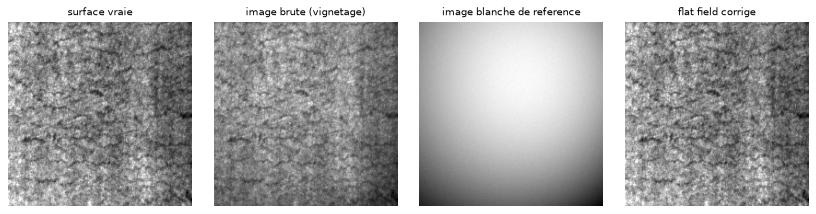

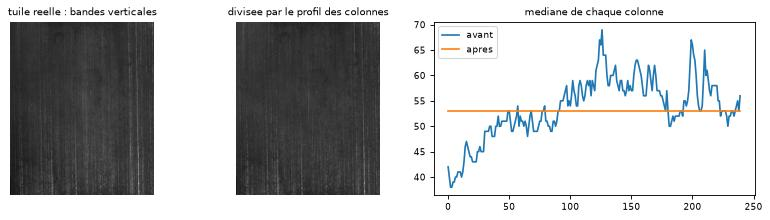

In [18]:
texture = read_image(CRAZING, cv2.IMREAD_GRAYSCALE).astype(np.float32)  # texture craquelee en float32 : la "surface vraie"
yy, xx = np.mgrid[0 : texture.shape[0], 0 : texture.shape[1]]  # np.mgrid : numero de ligne (yy) et de colonne (xx) de chaque pixel
# eclairage simule : vignetage (plus sombre loin du point (70, 60)) x degrade 0,8 -> 1,1 de gauche a droite
illum = (1 - 0.35 * (((xx - 70) / 140) ** 2 + ((yy - 60) / 140) ** 2)) * np.linspace(0.8, 1.1, texture.shape[1])[None, :]
dark_frame = 12 + rng.normal(0, 1, texture.shape)  # image "noire" (objectif bouche) : niveau 12 + bruit gaussien d'ecart-type 1
white_frame = 230 * illum + dark_frame  # image "blanche" de reference : surface uniforme (230) sous le meme eclairage, plus le noir
raw = texture * illum + dark_frame  # image brute simulee : surface x eclairage + noir
# flat field : (brute - noir) / (blanc - noir), puis remis a l'echelle par le niveau moyen du blanc
flat_field = (raw - dark_frame) / np.maximum(white_frame - dark_frame, 1) * (white_frame - dark_frame).mean()
grid(  # quatre images cote a cote
    [texture, raw, white_frame, flat_field],  # images
    ["surface vraie", "image brute (vignetage)", "image blanche de reference", "flat field corrige"],  # titres
    ncols=4,  # 4 images par ligne
)

tile_free = read_image(TILE_FREE, cv2.IMREAD_GRAYSCALE)  # tuile saine reelle, avec des bandes verticales
# mediane de chaque colonne (axis=0 : le long des lignes) : le profil du capteur
column_profile = np.median(tile_free.astype(np.float32), axis=0)
# divise chaque colonne par son profil ([None, :] : forme (1, W)), remet la moyenne, retour en uint8
columns_fixed = np.clip(tile_free / np.maximum(column_profile, 1)[None, :] * column_profile.mean(), 0, 255).astype(np.uint8)
# 3 cases, la derniere plus large pour la courbe
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), gridspec_kw={"width_ratios": [1, 1, 1.6]})
axes[0].imshow(tile_free, cmap="gray", vmin=0, vmax=255)  # image d'origine sur l'echelle 0-255
axes[0].set_title("tuile reelle : bandes verticales")  # titre de la case
axes[1].imshow(columns_fixed, cmap="gray", vmin=0, vmax=255)  # image corrigee
axes[1].set_title("divisee par le profil des colonnes")  # titre de la case
axes[0].axis("off")  # pas d'axes gradues
axes[1].axis("off")  # pas d'axes gradues
axes[2].plot(column_profile, label="avant")  # profil des colonnes avant
axes[2].plot(np.median(columns_fixed, axis=0), label="apres")  # profil apres correction : plat
axes[2].set_title("mediane de chaque colonne")  # titre de la courbe
axes[2].legend()  # legende avant / apres
plt.tight_layout()  # resserre les marges
plt.show()  # affiche la figure

## 6. Debruitage
| filtre | contre | prix |
|---|---|---|
| `GaussianBlur` | bruit gaussien leger | rapide ; floute aussi les bords et les rayures fines |
| `medianBlur` | bruit impulsionnel (pixels morts, poussieres) | rapide ; arrondit les coins |
| `bilateralFilter` | bruit en gardant les bords nets | moyen ; effet "peinture" si trop fort |
| `fastNlMeansDenoising` | bruit gaussien fort, textures repetitives | lent (dizaines de ms) ; trompe par les pixels morts |

Le bon filtre depend du TYPE de bruit : on compare ci-dessous sur un bruit gaussien (capteur, faible
lumiere) puis sur un bruit impulsionnel (pixels morts, poussieres). PSNR = ressemblance a l'image
propre, en dB (plus haut = mieux).

Piege : un debruitage trop fort efface les petits defauts. Le regler en regardant les defauts, pas
le fond, et le valider a la metrique du modele, jamais "a l'oeil sur une belle image".

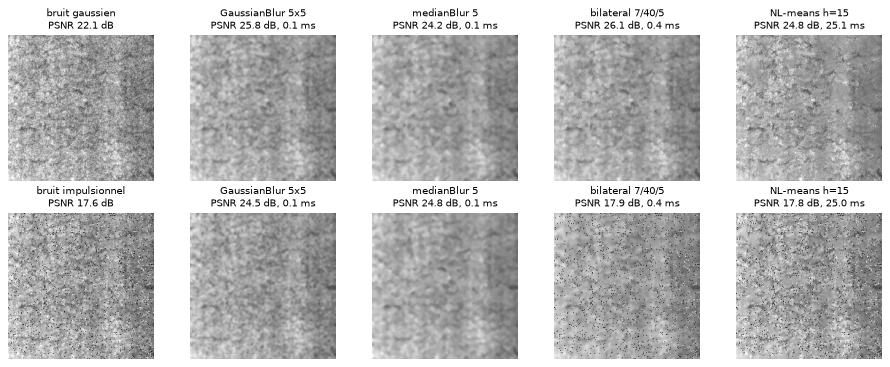

In [19]:
clean = read_image(CRAZING, cv2.IMREAD_GRAYSCALE)  # image propre de reference
# ajoute un bruit gaussien d'ecart-type 20, coupe a 0-255
gaussian_noise = np.clip(clean + rng.normal(0, 20, clean.shape), 0, 255).astype(np.uint8)
impulse_noise = clean.copy()  # copie a abimer avec du bruit impulsionnel
draw = rng.random(clean.shape)  # un nombre au hasard entre 0 et 1 par pixel
impulse_noise[draw < 0.03], impulse_noise[draw > 0.97] = 0, 255  # 6 % de pixels morts ou satures
filters = {  # les 4 filtres a comparer ; lambda = petite fonction sans nom : image -> image filtree
    "GaussianBlur 5x5": lambda im: cv2.GaussianBlur(im, (5, 5), 1.2),  # cv2.GaussianBlur(image, noyau 5 x 5, sigma 1,2)
    "medianBlur 5": lambda im: cv2.medianBlur(im, 5),  # cv2.medianBlur(image, 5) : mediane sur 5 x 5
    # cv2.bilateralFilter(image, diametre 7, sigmaColor 40, sigmaSpace 5) : moyenne seulement les voisins de niveau proche
    "bilateral 7/40/5": lambda im: cv2.bilateralFilter(im, 7, 40, 5),
    # cv2.fastNlMeansDenoising : moyenne de patchs 7 x 7 ressemblants, cherches dans 21 x 21 ; h = force du lissage
    "NL-means h=15": lambda im: cv2.fastNlMeansDenoising(im, None, h=15, templateWindowSize=7, searchWindowSize=21),
}
outputs, titles = [], []  # images et titres a afficher
for noise_name, noisy in (("bruit gaussien", gaussian_noise), ("bruit impulsionnel", impulse_noise)):  # pour chaque type de bruit
    outputs.append(noisy)  # d'abord l'image bruitee
    titles.append(f"{noise_name}\nPSNR {cv2.PSNR(clean, noisy):.1f} dB")  # cv2.PSNR(propre, autre) : ressemblance en dB (plus haut = mieux)
    for name, f in filters.items():  # pour chaque filtre
        start = time.perf_counter()  # chrono : perf_counter = horloge precise
        out = f(noisy)  # applique le filtre
        ms = (time.perf_counter() - start) * 1000  # duree en millisecondes
        outputs.append(out)  # image filtree
        titles.append(f"{name}\nPSNR {cv2.PSNR(clean, out):.1f} dB, {ms:.1f} ms")  # nom, PSNR et duree
grid(outputs, titles, ncols=5, size=2.3)  # 2 lignes de 5 : image bruitee + 4 filtres, pour chaque bruit

## 7. Nettete et mesure du flou
- **masque flou** (unsharp mask) : `image + a (image - flou)` avec `addWeighted` ; `a` de 0,5 a 1,5,
  sigma de l'ordre de la taille des details a renforcer ;
- **noyau laplacien** (`filter2D`) : renforcement plus brutal, amplifie le bruit ;
- **variance du laplacien** : mesure de nettete. En production, rejeter (ou signaler) les images
  floues (vibration, mise au point) avant le modele : seuil a fixer sur des images nettes connues.

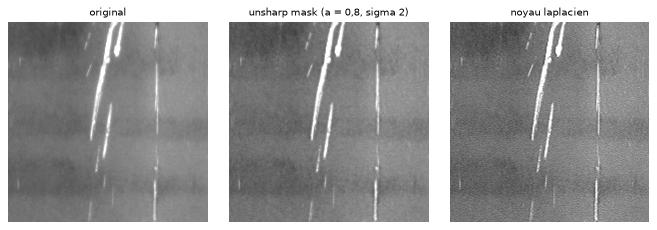

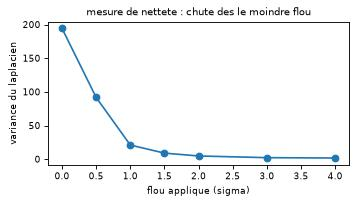

In [20]:
blur_ref = cv2.GaussianBlur(steel, (0, 0), 2)  # version floutee (sigma 2) de l'image d'acier
# cv2.addWeighted(a, 1.8, b, -0.8, 0) = 1,8 x image - 0,8 x flou = image + 0,8 x (image - flou)
unsharp = cv2.addWeighted(steel, 1.8, blur_ref, -0.8, 0)
# noyau 3 x 3 de renforcement : centre 5, voisins -1 (somme 1 : luminosite gardee)
laplace_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], np.float32)
laplace_sharp = cv2.filter2D(steel, -1, laplace_kernel)  # cv2.filter2D(image, -1 = meme type, noyau) : convolution de l'image par le noyau
# comparaison des trois versions
grid([steel, unsharp, laplace_sharp], ["original", "unsharp mask (a = 0,8, sigma 2)", "noyau laplacien"], ncols=3, size=2.8)

sigmas = [0, 0.5, 1, 1.5, 2, 3, 4]  # forces de flou a tester (0 = image d'origine)
sharpness = []  # mesure de nettete pour chaque flou
for s in sigmas:  # pour chaque force de flou
    im = steel if s == 0 else cv2.GaussianBlur(steel, (0, 0), s)  # image d'origine si 0, sinon floutee
    # cv2.Laplacian (derivee seconde, en float64) puis variance : beaucoup de bords nets = valeur haute
    sharpness.append(cv2.Laplacian(im, cv2.CV_64F).var())
plt.figure(figsize=(4.5, 2.6))  # nouvelle figure de 4,5 x 2,6 pouces
plt.plot(sigmas, sharpness, "o-")  # courbe nettete selon le flou, points relies ("o-")
plt.xlabel("flou applique (sigma)")  # nom de l'axe horizontal
plt.ylabel("variance du laplacien")  # nom de l'axe vertical
plt.title("mesure de nettete : chute des le moindre flou")  # titre de la courbe
plt.tight_layout()  # resserre les marges
plt.show()  # affiche la figure

## 8. Seuillage
- **fixe** : seulement si l'eclairage et le capteur sont stables (apres correction du shading) ;
- **Otsu** : seuil qui separe au mieux DEUX populations ; echoue si le defaut est minuscule (pas de
  second mode dans l'histogramme) ; **triangle** : mieux adapte a un petit pic de defaut ;
- **adaptatif** (`adaptiveThreshold`) : seuil = moyenne locale (fenetre `blockSize`, impaire) - `C` ;
  resiste au degrade ; `C` negatif pour garder ce qui est plus clair que son voisinage ;
- **hysteresis** : un seuil haut pour les "germes" surs, un seuil bas pour les etendre ; garde une
  fissure faible sur toute sa longueur sans ramasser le bruit (c'est l'idee de Canny).

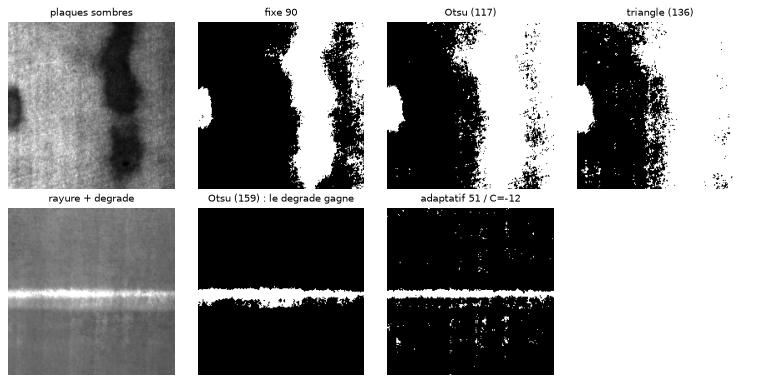

In [21]:
# cv2.threshold(image, seuil 90, valeur 255, type) ; BINARY_INV : 255 la ou le pixel <= 90 (zones sombres)
_, fixed = cv2.threshold(patches, 90, 255, cv2.THRESH_BINARY_INV)
# THRESH_OTSU : seuil calcule automatiquement (le 0 donne est ignore) ; t_otsu = seuil trouve
t_otsu, otsu = cv2.threshold(patches, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
# THRESH_TRIANGLE : autre seuil automatique, adapte a un petit pic de defaut
t_tri, tri = cv2.threshold(patches, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_TRIANGLE)
# Otsu sur la rayure + degrade ; BINARY : 255 au-dessus du seuil
t_band, otsu_band = cv2.threshold(band, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# cv2.adaptiveThreshold(image, 255, moyenne gaussienne locale, BINARY, fenetre 51, C=-12) : seuil = moyenne locale + 12
adaptive = cv2.adaptiveThreshold(band, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, -12)
grid(  # sept images
    [patches, fixed, otsu, tri, band, otsu_band, adaptive],  # images
    [  # titres
        "plaques sombres",  # titre 1
        "fixe 90",  # titre 2
        f"Otsu ({t_otsu:.0f})",  # titre 3, avec le seuil trouve
        f"triangle ({t_tri:.0f})",  # titre 4, avec le seuil trouve
        "rayure + degrade",  # titre 5
        f"Otsu ({t_band:.0f}) : le degrade gagne",  # titre 6, avec le seuil trouve
        "adaptatif 51 / C=-12",  # titre 7
    ],
    ncols=4,  # 4 images par ligne
    size=2.4,  # taille d'une case en pouces
)

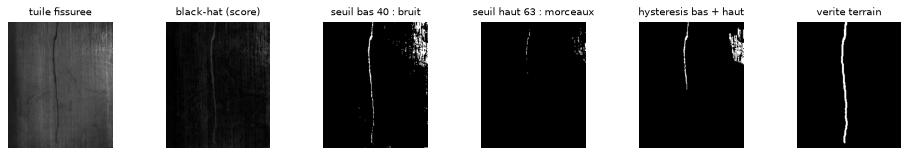

In [22]:
def hysteresis(score, low, high):  # seuillage par hysteresis ; renvoie un masque uint8 0 / 255
    """Garde les regions au-dessus de `low` qui contiennent au moins un pixel au-dessus de `high`."""
    weak = (score >= low).astype(np.uint8)  # pixels au-dessus du seuil bas (0 / 1)
    # cv2.connectedComponents : numero de region par pixel (0 = fond) ; connectivity=8 : diagonales comprises
    _, labels = cv2.connectedComponents(weak, connectivity=8)
    seeds = np.unique(labels[score >= high])  # numeros des regions qui contiennent au moins un pixel au-dessus du seuil haut
    return np.isin(labels, seeds[seeds > 0]).astype(np.uint8) * 255  # garde ces regions (isin), sauf le fond 0, en 0 / 255


crack_score = cv2.morphologyEx(tile, cv2.MORPH_BLACKHAT, ellipse21)  # ecart sombre au fond local
low, high = np.percentile(crack_score, (97, 99.7))  # seuil bas = percentile 97, seuil haut = percentile 99,7 du score
grid(  # six images
    [  # images
        tile,  # tuile d'origine
        crack_score,  # score black-hat
        ((crack_score >= low) * 255).astype(np.uint8),  # seuil bas seul : (booleen x 255) -> image 0 / 255
        ((crack_score >= high) * 255).astype(np.uint8),  # seuil haut seul
        hysteresis(crack_score, low, high),  # hysteresis
        crack_mask,  # verite terrain
    ],
    [  # titres
        "tuile fissuree",  # titre 1
        "black-hat (score)",  # titre 2
        f"seuil bas {low:.0f} : bruit",  # titre 3, avec le seuil
        f"seuil haut {high:.0f} : morceaux",  # titre 4, avec le seuil
        "hysteresis bas + haut",  # titre 5
        "verite terrain",  # titre 6
    ],
    ncols=6,  # 6 images sur une ligne
    size=2.0,  # taille d'une case en pouces
)

## 9. Morphologie mathematique
Sur une image binaire (ou grise), avec un element structurant (`getStructuringElement` : rectangle,
ellipse, croix, ou n'importe quel tableau de 0/1) :
- **erosion / dilatation** : amincit / epaissit ;
- **ouverture** (erosion puis dilatation) : supprime les petits points sans changer la taille du
  reste ; **fermeture** (dilatation puis erosion) : bouche les petits trous et recolle les morceaux ;
- **gradient** (dilatation - erosion) : le contour ;
- **element oriente** (un segment) : une ouverture par un segment ne garde que les structures assez
  longues dans cette direction ; l'union sur plusieurs angles garde tout ce qui est allonge (rayures)
  et elimine les taches rondes ;
- **squelette** (axe median d'un pixel) : longueur d'une fissure ; **remplissage des trous**.

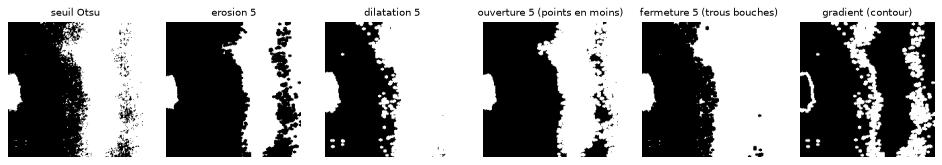

In [23]:
binary = otsu.copy()  # copie du masque Otsu des plaques
k5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))  # element structurant en disque 5 x 5
grid(  # six operations cote a cote
    [  # images
        binary,  # binaire d'origine
        cv2.erode(binary, k5),  # cv2.erode : un pixel reste blanc si tout son voisinage (k5) l'est : amincit
        cv2.dilate(binary, k5),  # cv2.dilate : un pixel devient blanc si un voisin l'est : epaissit
        cv2.morphologyEx(binary, cv2.MORPH_OPEN, k5),  # ouverture : erosion puis dilatation
        cv2.morphologyEx(binary, cv2.MORPH_CLOSE, k5),  # fermeture : dilatation puis erosion
        cv2.morphologyEx(binary, cv2.MORPH_GRADIENT, k5),  # gradient : dilatation - erosion = contour
    ],
    # titres
    ["seuil Otsu", "erosion 5", "dilatation 5", "ouverture 5 (points en moins)", "fermeture 5 (trous bouches)", "gradient (contour)"],
    ncols=6,  # 6 images sur une ligne
    size=2.0,  # taille d'une case en pouces
)

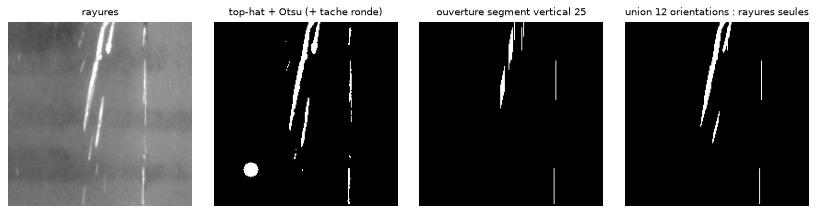

In [24]:
def line_kernel(length, angle_deg):  # element structurant en forme de segment ; renvoie un tableau 0 / 1
    """Element structurant en segment de `length` pixels, oriente de `angle_deg` degres."""
    k = np.zeros((length, length), np.uint8)  # carre de zeros length x length
    c = length // 2  # centre du carre
    # demi-segment projete en x et en y ; signe - car l'axe y descend dans une image
    dx, dy = np.cos(np.deg2rad(angle_deg)) * c, -np.sin(np.deg2rad(angle_deg)) * c
    cv2.line(k, (round(c - dx), round(c - dy)), (round(c + dx), round(c + dy)), 1, 1)  # trace le segment (valeur 1, epaisseur 1)
    return k  # l'element structurant


def elongated(binary, length=25, step=15):  # garde les structures allongees, quelle que soit leur direction ; renvoie un binaire
    """Union des ouvertures par des segments orientes : garde les structures longues de `length` px."""
    # ouverture par un segment tous les 15 degres (12 orientations), puis maximum pixel a pixel = union
    return np.max([cv2.morphologyEx(binary, cv2.MORPH_OPEN, line_kernel(length, a)) for a in range(0, 180, step)], axis=0)


bright = cv2.morphologyEx(steel, cv2.MORPH_TOPHAT, ellipse21)  # top-hat : rayures claires plus fines que 21 pixels
_, bright_bin = cv2.threshold(bright, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)  # binarisation Otsu
bright_bin = cv2.bitwise_or(bright_bin, cv2.circle(np.zeros_like(bright_bin), (40, 160), 8, 255, -1))  # une tache ronde ajoutee
# ouverture par un segment vertical (90 degres) de 25 px : ne garde que le vertical
vertical = cv2.morphologyEx(bright_bin, cv2.MORPH_OPEN, line_kernel(25, 90))
grid(  # quatre images
    [steel, bright_bin, vertical, elongated(bright_bin)],  # images
    ["rayures", "top-hat + Otsu (+ tache ronde)", "ouverture segment vertical 25", "union 12 orientations : rayures seules"],  # titres
    ncols=4,  # 4 images par ligne
)

fissure : 1064 pixels, squelette 251 px ~ longueur 12.6 mm


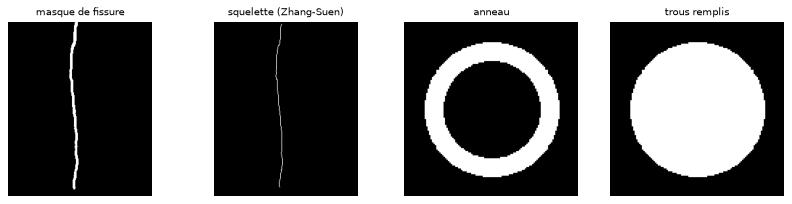

In [25]:
def thinning(binary):  # squelette d'un binaire (1 pixel d'epaisseur) ; renvoie une image 0 / 255
    """Amincissement de Zhang-Suen : squelette connexe d'un pixel (sans le module contrib ximgproc)."""
    img = np.pad((binary > 0).astype(np.uint8), 1)  # binaire 0 / 1 entoure d'une bordure de zeros (np.pad) : chaque pixel a 8 voisins
    changed = True  # drapeau : un pixel a-t-il ete efface pendant ce passage ?
    while changed:  # tant qu'on efface encore des pixels
        changed = False  # on suppose que ce passage sera le dernier
        for step in (0, 1):  # deux sous-passages (conditions un peu differentes)
            p = img  # p : simple autre nom de l'image
            # voisins decales : p2 = haut, p3 = haut-droite, p4 = droite, p5 = bas-droite
            p2, p3, p4, p5 = p[:-2, 1:-1], p[:-2, 2:], p[1:-1, 2:], p[2:, 2:]
            p6, p7, p8, p9 = p[2:, 1:-1], p[2:, :-2], p[1:-1, :-2], p[:-2, :-2]  # p6 = bas, p7 = bas-gauche, p8 = gauche, p9 = haut-gauche
            ring = [p2, p3, p4, p5, p6, p7, p8, p9, p2]  # les 8 voisins dans l'ordre du tour, p2 repete pour fermer le tour
            neighbours = sum(n.astype(np.int32) for n in ring[:8])  # nombre de voisins blancs de chaque pixel
            # nombre de passages 0 -> 1 en faisant le tour
            transitions = sum(((ring[i] == 0) & (ring[i + 1] == 1)).astype(np.int32) for i in range(8))
            if step == 0:  # premier sous-passage
                cond = (p2 * p4 * p6 == 0) & (p4 * p6 * p8 == 0)  # condition de Zhang-Suen : efface les pixels du bord bas-droit
            else:  # sinon (second sous-passage)
                cond = (p2 * p4 * p8 == 0) & (p2 * p6 * p8 == 0)  # efface les pixels du bord haut-gauche
            # pixel blanc, 2 a 6 voisins, une seule transition, et la condition : il peut etre efface
            remove = (p[1:-1, 1:-1] == 1) & (neighbours >= 2) & (neighbours <= 6) & (transitions == 1) & cond
            if remove.any():  # si au moins un pixel est a effacer
                img[1:-1, 1:-1][remove] = 0  # on les efface (dans l'image elle-meme)
                changed = True  # il faudra refaire un passage
    return img[1:-1, 1:-1] * 255  # retire la bordure ajoutee, en 0 / 255


def fill_holes(binary):  # remplit les trous interieurs d'un binaire ; renvoie un binaire 0 / 255
    """Remplit les trous interieurs : inonder le fond depuis le bord ; ce qui n'est pas atteint est un trou."""
    # binaire 0 / 255 avec une bordure noire de 1 pixel : le fond touche forcement le coin (0, 0)
    b = cv2.copyMakeBorder((binary > 0).astype(np.uint8) * 255, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
    flood = b.copy()  # copie qu'on va inonder
    # cv2.floodFill(image, masque de travail 2 px plus grand, depart (0, 0), valeur 255) : remplit le fond exterieur
    cv2.floodFill(flood, np.zeros((b.shape[0] + 2, b.shape[1] + 2), np.uint8), (0, 0), 255)
    return (b | cv2.bitwise_not(flood))[1:-1, 1:-1]  # objet OU non inonde (= trous) ; [1:-1, 1:-1] retire la bordure


skeleton = thinning(crack_mask)  # squelette du masque de fissure
# anneau de test : cercle de rayon 40, trait de 12 px, dans une image 120 x 120
ring_shape = cv2.circle(np.zeros((120, 120), np.uint8), (60, 60), 40, 255, 12)
print(  # longueur ~ nombre de pixels du squelette x taille d'un pixel
    f"fissure : {np.count_nonzero(crack_mask)} pixels, squelette {np.count_nonzero(skeleton)} px ~ longueur {np.count_nonzero(skeleton) * MM_PER_PX:.1f} mm"
)
grid(  # quatre images
    [crack_mask, skeleton, ring_shape, fill_holes(ring_shape)],  # images
    ["masque de fissure", "squelette (Zhang-Suen)", "anneau", "trous remplis"],  # titres
    ncols=4,  # 4 images par ligne
)

## 10. Contours et mesures
`findContours` (sur un binaire 0/255) renvoie le contour de chaque objet ; `RETR_EXTERNAL` ignore
les trous interieurs. Par contour : aire, perimetre, boite englobante droite (`boundingRect`) ou
orientee (`minAreaRect` : longueur, largeur, angle), ellipse ajustee, enveloppe convexe (solidite =
aire / aire de l'enveloppe), moments (centre de gravite), circularite 4 pi A / P^2 (1 = disque).
Ces mesures font un classifieur de forme simple et explicable : allonge = fissure ou rayure,
rond = trou ou piqure, le reste = tache.

**Conversion en mm** : photographier une mire (ou une piece de cote connue) a la distance de
travail : `mm_par_px = cote_mm / cote_px` ; longueur en mm = px x echelle, aire en mm2 = px x echelle^2.
Valable si l'image est redressee (section 3) et la distance constante.

Piege : `contourArea` mesure le polygone passant par les centres des pixels de bord : pour un objet
fin, il sous-estime beaucoup le nombre de pixels (une ligne d'un pixel a une aire nulle). Pour les
petits defauts, compter les pixels (`connectedComponentsWithStats`, section 11).

MT_Crack     fissure/rayure  L=12.65 mm  l=0.62 mm  aire= 2.02 mm2  angle= -0.3  circ=0.03  solid=0.33
MT_Blowhole  trou/piqure     L= 0.65 mm  l=0.40 mm  aire= 0.20 mm2  angle=-90.0  circ=0.78  solid=0.96


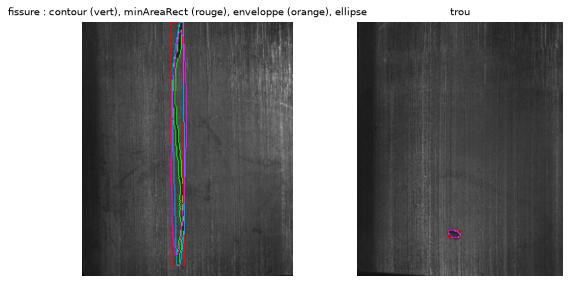

In [26]:
# mesures de forme d'un contour ; renvoie un dictionnaire (centre, aire, longueur, largeur, angle, type...)
def measure(contour, mm_per_px=MM_PER_PX):
    """Mesures de forme d'un contour, longueurs en mm."""
    area = cv2.contourArea(contour)  # cv2.contourArea : aire du polygone du contour, en pixels
    perimeter = cv2.arcLength(contour, True)  # cv2.arcLength(contour, ferme=True) : perimetre en pixels
    # cv2.minAreaRect : plus petit rectangle oriente qui contient le contour : centre, (cotes), angle
    (cx, cy), (rw, rh), angle = cv2.minAreaRect(contour)
    length, width = max(rw, rh), max(min(rw, rh), 1.0)  # longueur = grand cote, largeur = petit cote (au moins 1 pour eviter / 0)
    # cv2.convexHull : enveloppe convexe (elastique tendu autour du contour), puis son aire
    hull_area = cv2.contourArea(cv2.convexHull(contour))
    m = cv2.moments(contour)  # cv2.moments : sommes ponderees sur la forme (aire m00 ; centre = m10 / m00, m01 / m00)
    circularity = 4 * np.pi * area / max(perimeter**2, 1e-6)  # circularite 4 pi A / P^2 : 1 pour un disque parfait
    elongation = length / width  # allongement = longueur / largeur
    # regle simple : tres allonge = fissure/rayure ; sinon assez rond = trou/piqure ; sinon tache
    kind = "fissure/rayure" if elongation > 4 else ("trou/piqure" if circularity > 0.7 else "tache")
    return {  # dictionnaire des mesures
        "centre_x": m["m10"] / m["m00"] if m["m00"] else cx,  # centre de gravite x = m10 / m00 ; si l'aire est nulle, centre du rectangle
        "centre_y": m["m01"] / m["m00"] if m["m00"] else cy,  # idem en y
        "aire_mm2": area * mm_per_px**2,  # aire en mm2 = aire en pixels x (mm par pixel) au carre
        "longueur_mm": length * mm_per_px,  # longueur en mm
        "largeur_mm": width * mm_per_px,  # largeur en mm
        "angle": angle,  # angle du rectangle oriente, en degres
        "solidite": area / max(hull_area, 1e-6),  # solidite = aire / aire de l'enveloppe convexe (1 = forme pleine, sans creux)
        "circularite": circularity,  # 1 pour un disque, proche de 0 pour une forme allongee
        "type": kind,  # classe de forme deduite
    }


canvas = []  # images annotees a afficher
for path in (TILE_CRACK, TILE_HOLE):  # pour la tuile fissuree puis la tuile trouee
    image, mask = read_image(path, cv2.IMREAD_GRAYSCALE), mask_of(path)  # l'image en gris et son masque de verite terrain
    # cv2.findContours(binaire, RETR_EXTERNAL = contours exterieurs seuls, CHAIN_APPROX_SIMPLE = points utiles seuls)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    view = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)  # copie couleur pour dessiner
    for c in contours:  # pour chaque objet
        if cv2.contourArea(c) < 5:  # si l'objet est minuscule (aire < 5 pixels)
            continue  # on passe au suivant
        info = measure(c)  # ses mesures
        # cv2.boxPoints : les 4 coins du rectangle oriente, en entiers pour le dessin
        box = cv2.boxPoints(cv2.minAreaRect(c)).astype(np.int32)
        # cv2.drawContours(image, [contours], -1 = tous, couleur, epaisseur) : contour en vert
        cv2.drawContours(view, [c], -1, (0, 255, 0), 1)
        cv2.drawContours(view, [box], -1, (0, 0, 255), 1)  # rectangle oriente en rouge
        cv2.drawContours(view, [cv2.convexHull(c)], -1, (255, 160, 0), 1)  # enveloppe convexe en orange
        if len(c) >= 5:  # fitEllipse exige au moins 5 points
            cv2.ellipse(view, cv2.fitEllipse(c), (255, 0, 255), 1)  # cv2.fitEllipse ajuste une ellipse ; cv2.ellipse la dessine en violet
        print(  # une ligne de mesures par objet
            f"{path.parent.parent.name:12s} {info['type']:15s} L={info['longueur_mm']:5.2f} mm  l={info['largeur_mm']:4.2f} mm  "
            f"aire={info['aire_mm2']:5.2f} mm2  angle={info['angle']:5.1f}  circ={info['circularite']:.2f}  solid={info['solidite']:.2f}"
        )
    canvas.append(view)  # image annotee de cette tuile
# les deux tuiles annotees
grid(canvas, ["fissure : contour (vert), minAreaRect (rouge), enveloppe (orange), ellipse", "trou"], ncols=2, size=3.6)

## 11. Composantes connexes
`connectedComponentsWithStats` etiquette chaque objet d'un binaire et donne en un seul appel sa boite,
son NOMBRE DE PIXELS et son centre. Usage typique : supprimer les objets trop petits (bruit), compter
les defauts, ne garder que le plus gros. `connectivity=8` relie les pixels en diagonale (fissures).

17 composantes, 7 gardees (au moins 30 pixels)


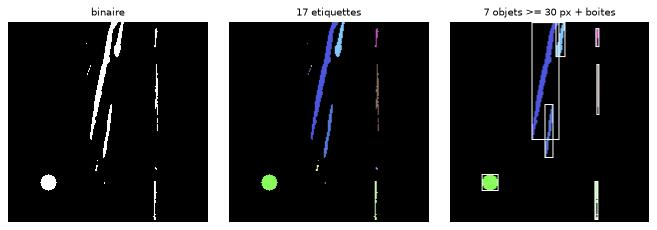

In [27]:
objects_bin = bright_bin  # rayures + tache ronde + poussiere de pixels isoles (section 9)
# cv2.connectedComponentsWithStats : nb d'etiquettes, image des etiquettes, stats (boite, aire), centres
n, labels, stats, centroids = cv2.connectedComponentsWithStats(objects_bin, connectivity=8)
min_area = 30  # aire minimale en pixels pour garder un objet
keep = [i for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_area]  # objets (fond 0 exclu) d'au moins min_area pixels
print(f"{n - 1} composantes, {len(keep)} gardees (au moins {min_area} pixels)")  # bilan du filtrage
palette = np.vstack([[0, 0, 0], rng.integers(60, 255, size=(n - 1, 3))]).astype(np.uint8)  # une couleur par etiquette
colored = palette[labels]  # palette[labels] : chaque pixel prend la couleur de son etiquette
kept = colored.copy()  # copie
kept[~np.isin(labels, keep)] = 0  # efface (noir) les objets trop petits
for i in keep:  # pour chaque objet garde
    x, y, bw, bh, area = stats[i]  # sa boite (x, y, largeur, hauteur) et son aire en pixels
    # cv2.rectangle(image, coin haut-gauche, coin bas-droit, couleur, epaisseur) : sa boite en blanc
    cv2.rectangle(kept, (int(x), int(y)), (int(x + bw - 1), int(y + bh - 1)), (255, 255, 255), 1)
# binaire, etiquettes en couleur, objets gardes avec leur boite
grid([objects_bin, colored, kept], ["binaire", f"{n - 1} etiquettes", f"{len(keep)} objets >= {min_area} px + boites"], ncols=3, size=2.8)

## 12. Bords et gradients
- **Sobel** (derivee en x ou en y, `ksize` 3 ou 5) et **Scharr** (plus precis en 3x3) : sortie en
  `CV_32F` (des valeurs negatives existent : en `uint8` on perd la moitie des bords) ;
  amplitude = `cv2.magnitude(gx, gy)`, orientation = `cv2.phase(gx, gy)` ;
- **Laplacien** : derivee seconde, repond aux points et aux lignes fines, tres sensible au bruit ;
- **Canny** : bords d'un pixel, avec deux seuils (hysteresis). Regle courante : seuils a
  (1 -/+ 0,33) x mediane. Sur une texture d'acier, mieux vaut des percentiles de l'amplitude du
  gradient (ici 90 et 97 %) apres un leger flou.

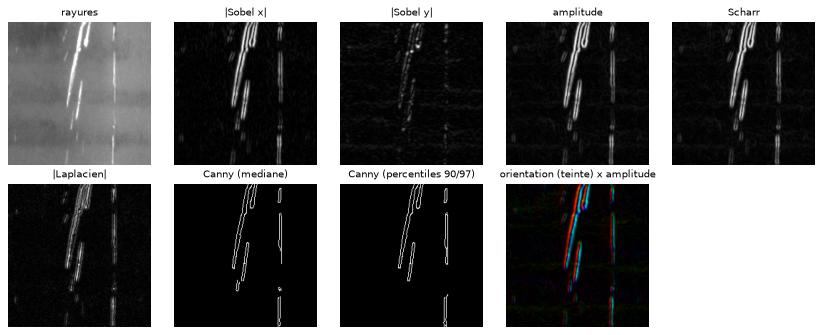

In [28]:
smooth = cv2.GaussianBlur(steel, (5, 5), 1.0)  # leger flou 5 x 5 (sigma 1) pour ne pas detecter le bruit
gx = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)  # cv2.Sobel(image, sortie float32, dx=1, dy=0, ksize=3) : derivee en x (bords verticaux)
gy = cv2.Sobel(smooth, cv2.CV_32F, 0, 1, ksize=3)  # derivee en y (bords horizontaux)
magnitude = cv2.magnitude(gx, gy)  # cv2.magnitude : amplitude du gradient = racine(gx^2 + gy^2)
# cv2.Scharr : derivee 3 x 3 plus precise que Sobel ; amplitude des deux directions
scharr = cv2.magnitude(cv2.Scharr(smooth, cv2.CV_32F, 1, 0), cv2.Scharr(smooth, cv2.CV_32F, 0, 1))
laplacian = np.abs(cv2.Laplacian(smooth, cv2.CV_32F, ksize=3))  # valeur absolue du laplacien (derivee seconde)
median = float(np.median(smooth))  # niveau de gris median de l'image
# cv2.Canny(image, seuil bas, seuil haut) : bords d'un pixel ; seuils a 0,67 et 1,33 x la mediane
canny_median = cv2.Canny(smooth, int(max(0, 0.67 * median)), int(min(255, 1.33 * median)))
lo, hi = np.percentile(magnitude, (90, 97))  # meme gradient que Canny avec L2gradient=True
canny_pct = cv2.Canny(smooth, lo, hi, L2gradient=True)  # L2gradient=True : amplitude exacte racine(gx^2 + gy^2) au lieu de |gx| + |gy|
grad8 = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)  # amplitude ramenee a 0-255 (min-max) en uint8
angle = cv2.phase(gx, gy, angleInDegrees=True)  # cv2.phase : orientation du gradient en degres (0-360)
# image HSV : teinte = angle / 2 (0-179), saturation 255, valeur = amplitude
hsv_grad = np.dstack([(angle / 2).astype(np.uint8), np.full_like(steel, 255), grad8])
orientation = cv2.cvtColor(hsv_grad, cv2.COLOR_HSV2BGR)  # HSV -> BGR pour l'affichage
grid(  # neuf images
    [steel, np.abs(gx), np.abs(gy), magnitude, scharr, laplacian, canny_median, canny_pct, orientation],  # images
    [  # titres
        "rayures",  # titre 1
        "|Sobel x|",  # titre 2
        "|Sobel y|",  # titre 3
        "amplitude",  # titre 4
        "Scharr",  # titre 5
        "|Laplacien|",  # titre 6
        "Canny (mediane)",  # titre 7
        "Canny (percentiles 90/97)",  # titre 8
        "orientation (teinte) x amplitude",  # titre 9
    ],
    ncols=5,  # 5 images par ligne
    size=2.1,  # taille d'une case en pouces
)

## 13. Transformee de Hough : lignes et cercles
- `HoughLinesP` (sur une image de bords) : segments ; `threshold` = nombre de votes minimal,
  `minLineLength` et `maxLineGap` en pixels. Pour mesurer l'angle des rayures, l'alignement d'une
  bande ou une rive ;
- `HoughCircles` (sur l'image grise lissee) : `param1` = seuil haut de Canny interne, `param2` = votes
  (plus petit = plus de cercles, plus de fausses detections), `minRadius`/`maxRadius` indispensables.
  Pour centrer une piece ronde (section 3), mesurer un trou.

6 segments ; angle median 97.5 degres
cercles (x, y, r) a l'echelle 300 px : [[151, 151, 133]]


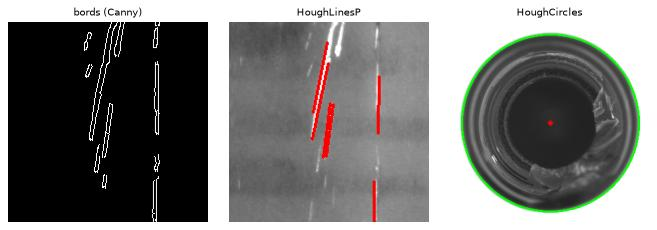

In [29]:
edges = cv2.Canny(cv2.GaussianBlur(steel, (5, 5), 1.2), 30, 90)  # bords Canny (seuils 30 et 90) apres un flou
# cv2.HoughLinesP(bords, pas 1 px, pas 1 degre, 40 votes min, longueur min 40 px, trou max 6 px) : segments
lines = cv2.HoughLinesP(edges, rho=1, theta=np.pi / 180, threshold=40, minLineLength=40, maxLineGap=6)
lines_view = cv2.cvtColor(steel, cv2.COLOR_GRAY2BGR)  # copie couleur pour dessiner
angles = []  # angle de chaque segment
for x1, y1, x2, y2 in [] if lines is None else lines.reshape(-1, 4):  # forme (N, 1, 4) ou (N, 4) selon la version
    cv2.line(lines_view, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 2)  # segment en rouge, epaisseur 2
    angles.append(np.degrees(np.arctan2(y2 - y1, x2 - x1)) % 180)  # angle en degres (arctan2), ramene a 0-180 (% 180)
# nombre de segments et angle median
print(f"{0 if lines is None else len(lines)} segments ; angle median {np.median(angles) if angles else float('nan'):.1f} degres")

small_bottle = cv2.resize(bottle_g, (300, 300), interpolation=cv2.INTER_AREA)  # bouteille reduite a 300 x 300 (Hough plus rapide)
circles = cv2.HoughCircles(  # cv2.HoughCircles : detection de cercles
    cv2.GaussianBlur(small_bottle, (7, 7), 2),  # image grise lissee (flou 7 x 7) : moins de faux cercles
    cv2.HOUGH_GRADIENT,  # methode de detection, par le gradient
    dp=1.2,  # resolution inverse de la grille de votes (1,2 : un peu plus grossiere que l'image)
    minDist=40,  # distance minimale entre deux centres, en pixels
    param1=100,  # seuil haut du Canny interne
    param2=40,  # votes minimaux : plus petit = plus de cercles, mais plus de faux
    minRadius=40,  # rayon minimal en pixels
    maxRadius=150,  # rayon maximal en pixels
)
circles_view = cv2.cvtColor(small_bottle, cv2.COLOR_GRAY2BGR)  # copie couleur pour dessiner
circles = None if circles is None else circles.reshape(-1, 3)[:1]  # le cercle le mieux vote (les suivants sont souvent faux)
for x, y, r in [] if circles is None else np.round(circles).astype(int):  # pour chaque cercle (coordonnees arrondies en entiers)
    cv2.circle(circles_view, (int(x), int(y)), int(r), (0, 255, 0), 2)  # le cercle en vert
    cv2.circle(circles_view, (int(x), int(y)), 2, (0, 0, 255), 3)  # son centre en rouge
print("cercles (x, y, r) a l'echelle 300 px :", None if circles is None else np.round(circles).astype(int).tolist())  # cercles trouves
grid([edges, lines_view, circles_view], ["bords (Canny)", "HoughLinesP", "HoughCircles"], ncols=3, size=2.8)  # bords, segments, cercle

## 14. Frequences et texture
### Spectre de Fourier
`np.fft.fft2` + `fftshift` (frequence nulle au centre) ; on affiche `log(1 + |F|)`. Une structure
orientee donne une ligne PERPENDICULAIRE dans le spectre ; un motif periodique (trame, vibration,
texture de laminage) donne des pics isoles, faciles a supprimer.

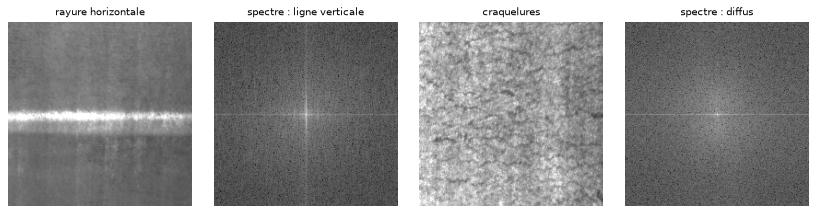

In [30]:
def spectrum(image):  # spectre de Fourier d'une image ; renvoie log(1 + |F|) a afficher
    # np.fft.fft2 : transformee de Fourier 2D ; fftshift met la frequence nulle au centre
    f = np.fft.fftshift(np.fft.fft2(image.astype(np.float32)))
    return np.log1p(np.abs(f))  # log1p = log(1 + x) : compresse les tres grandes valeurs pour l'affichage


grid(  # images et spectres
    [band, spectrum(band), read_image(CRAZING, 0), spectrum(read_image(CRAZING, 0))],  # flag 0 = lecture en gris
    ["rayure horizontale", "spectre : ligne verticale", "craquelures", "spectre : diffus"],  # titres
    ncols=4,  # 4 images par ligne
)

### Supprimer une trame periodique (filtre notch) ; passe-bas et passe-haut
On repere les pics du spectre hors du centre, on les met a zero (petits disques), on revient a
l'image (`ifft2`). Le defaut, qui n'est pas periodique, est garde. Passe-bas gaussien = flou ;
passe-haut = image - flou (detail, comme le top-hat mais sans forme d'element).

PSNR : avec trame 23.2 dB -> apres notch 28.8 dB


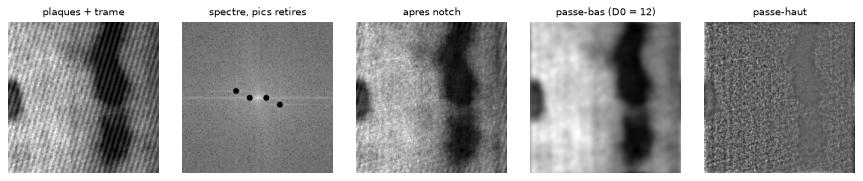

In [31]:
# filtre coupe-bande (notch) : retire les pics periodiques ; renvoie (image filtree, spectre, masque garde)
def notch_filter(image, n_peaks=2, exclude=8, radius=4):
    """Supprime les `n_peaks` pics les plus forts du spectre hors du centre (et leurs symetriques)."""
    f = np.fft.fftshift(np.fft.fft2(image.astype(np.float32)))  # spectre centre
    mag = np.log1p(np.abs(f))  # amplitude du spectre en echelle log
    h, w = image.shape  # hauteur et largeur
    yy, xx = np.mgrid[0:h, 0:w]  # coordonnees de chaque point du spectre
    dist = np.hypot(yy - h // 2, xx - w // 2)  # distance de chaque point au centre (frequence nulle)
    search = np.where(dist > exclude, mag, 0)  # spectre ou l'on cherche les pics : centre (basses frequences) exclu
    keep = np.ones((h, w), np.float32)  # masque de 1 : frequences gardees
    for _ in range(n_peaks):  # pour chacun des n_peaks pics a retirer
        # position du point le plus fort (argmax a plat, puis unravel_index -> ligne, colonne)
        py, px = np.unravel_index(np.argmax(search), search.shape)
        for y0, x0 in ((py, px), (2 * (h // 2) - py, 2 * (w // 2) - px)):  # le pic et son symetrique
            hit = np.hypot(yy - y0, xx - x0) <= radius  # petit disque de rayon radius autour du pic
            keep[hit] = 0  # ces frequences seront mises a zero
            search[hit] = 0  # et ne seront plus cherchees
    restored = np.real(np.fft.ifft2(np.fft.ifftshift(f * keep)))  # ifftshift puis ifft2 : retour a l'image ; np.real garde la partie reelle
    return np.clip(restored, 0, 255).astype(np.uint8), mag, keep  # image ramenee en uint8, spectre, masque


yy, xx = np.mgrid[0 : patches.shape[0], 0 : patches.shape[1]]  # coordonnees de chaque pixel des plaques
pattern = 25 * np.sin(2 * np.pi * (xx / 7.0 + yy / 23.0))  # trame (interference, vibration)
with_pattern = np.clip(patches + pattern, 0, 255).astype(np.uint8)  # plaques + trame, ramenees en uint8
restored, mag, keep = notch_filter(with_pattern)  # filtre notch
# PSNR avant / apres : doit monter
print(f"PSNR : avec trame {cv2.PSNR(patches, with_pattern):.1f} dB -> apres notch {cv2.PSNR(patches, restored):.1f} dB")

f = np.fft.fftshift(np.fft.fft2(patches.astype(np.float32)))  # spectre centre des plaques
d2 = (yy - patches.shape[0] // 2) ** 2 + (xx - patches.shape[1] // 2) ** 2  # distance au carre de chaque frequence au centre
low_pass_h = np.exp(-d2 / (2 * 12.0**2))  # filtre passe-bas gaussien : 1 au centre, decroit avec la distance (D0 = 12)
low_pass = np.real(np.fft.ifft2(np.fft.ifftshift(f * low_pass_h)))  # garde les basses frequences : image floutee
high_pass = np.real(np.fft.ifft2(np.fft.ifftshift(f * (1 - low_pass_h))))  # garde le complement (1 - passe-bas) : les details
grid(  # cinq images
    [with_pattern, mag * keep, restored, low_pass, high_pass],  # mag * keep : spectre avec les pics retires
    ["plaques + trame", "spectre, pics retires", "apres notch", "passe-bas (D0 = 12)", "passe-haut"],  # titres
    ncols=5,  # 5 images sur une ligne
    size=2.2,  # taille d'une case en pouces
)

### Filtres de Gabor orientes : les rayures
Un filtre de Gabor = une onde (longueur `lambd`) dans une gaussienne (`sigma`), orientee (`theta`).
Une banque de 12 orientations : la reponse maximale fait ressortir les structures lineaires et
l'orientation gagnante donne leur direction. Reglage : `lambd` de l'ordre de 2 fois la largeur de la
rayure, `sigma` ~ 0,5 `lambd`, `gamma` < 1 allonge le filtre (plus selectif en direction). Retirer la
moyenne du noyau pour que les zones uniformes repondent 0.

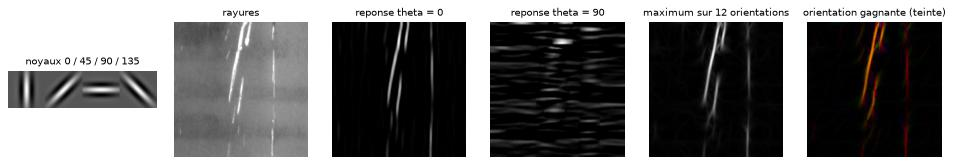

In [32]:
# banque de filtres de Gabor, un par orientation ; renvoie un dict angle -> noyau
def gabor_bank(lambd=10.0, sigma=4.0, gamma=0.4, ksize=31, step=15):
    bank = {}  # dictionnaire vide a remplir
    for a in range(0, 180, step):  # pour chaque angle de 0 a 165 degres, tous les 15 degres
        # cv2.getGaborKernel((taille), sigma, theta en radians, longueur d'onde, gamma, psi = phase, type float32)
        k = cv2.getGaborKernel((ksize, ksize), sigma, np.deg2rad(a), lambd, gamma, psi=0, ktype=cv2.CV_32F)
        bank[a] = k - k.mean()  # retire la moyenne : une zone uniforme donne une reponse nulle
    return bank  # les 12 noyaux


bank = gabor_bank()  # 12 noyaux avec les reglages par defaut
img32 = steel.astype(np.float32)  # image en float32 (les reponses peuvent etre negatives)
# filtre l'image par chaque noyau, puis empile : forme (12, H, W)
responses = np.stack([cv2.filter2D(img32, cv2.CV_32F, k) for k in bank.values()])
best = responses.max(axis=0)  # reponse maximale sur les 12 orientations, pixel par pixel
best_angle = np.array(list(bank))[responses.argmax(axis=0)]  # angle du noyau gagnant pour chaque pixel
angle_view = cv2.cvtColor(  # image couleur : teinte = orientation, luminosite = force
    np.dstack(  # empile 3 plans en une image HSV
        [  # les 3 plans
            (best_angle).astype(np.uint8),  # H : angle gagnant (0-165, dans l'echelle 0-179 d'OpenCV)
            np.full_like(steel, 255),  # S : saturation maximale partout
            cv2.normalize(np.maximum(best, 0), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8),  # V : reponse positive ramenee a 0-255
        ]
    ),
    cv2.COLOR_HSV2BGR,  # conversion HSV -> BGR
)
kernels = cv2.hconcat(  # 4 noyaux agrandis colles cote a cote, pour les voir
    # chaque noyau 31 x 31 -> 60 x 60, ramene a 0-255
    [cv2.normalize(cv2.resize(bank[a], (60, 60)), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8) for a in (0, 45, 90, 135)]
)
grid(  # six images
    # reponses negatives mises a 0 (np.maximum) ; responses[6] = angle 90
    [kernels, steel, np.maximum(responses[0], 0), np.maximum(responses[6], 0), np.maximum(best, 0), angle_view],
    [  # titres
        "noyaux 0 / 45 / 90 / 135",  # titre 1
        "rayures",  # titre 2
        "reponse theta = 0",  # titre 3
        "reponse theta = 90",  # titre 4
        "maximum sur 12 orientations",  # titre 5
        "orientation gagnante (teinte)",  # titre 6
    ],
    ncols=6,  # 6 images sur une ligne
    size=2.0,  # taille d'une case en pouces
)

### LBP (motifs binaires locaux) et energie locale
- **LBP** : chaque pixel est code par la comparaison a ses 8 voisins (un octet) ; l'histogramme des
  codes est une signature de texture insensible a l'eclairage (seul l'ordre compte). Deux images de la
  meme texture ont des histogrammes proches (`compareHist`) : controle d'aspect, tri de bobines ;
- **energie locale** (ecart-type dans une fenetre, par deux `boxFilter`) : carte simple et rapide
  ou une rupture de texture (fissure, zone lisse) ressort.

distance chi2 entre histogrammes LBP (petite = meme texture) :
                craquelures 1  craquelures 2     calamine 1     calamine 2
craquelures 1           0.000          0.016          0.209          0.144
craquelures 2           0.016          0.000          0.245          0.179
calamine 1              0.209          0.245          0.000          0.030
calamine 2              0.144          0.179          0.030          0.000


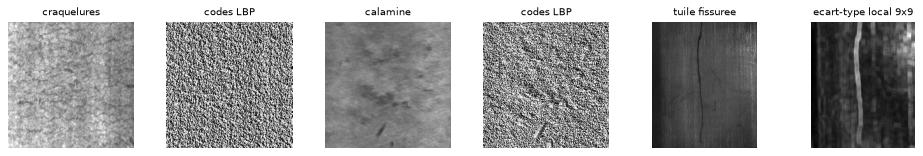

In [33]:
def lbp(gray):  # code LBP de chaque pixel ; renvoie une image uint8 (bord d'un pixel retire)
    """LBP 8 voisins, rayon 1, ecrit en numpy (un octet par pixel)."""
    g = gray.astype(np.int16)  # int16 : comparaisons sans souci de type
    c = g[1:-1, 1:-1]  # pixels centraux (sans le bord d'un pixel)
    h, w = g.shape  # hauteur et largeur
    code = np.zeros(c.shape, np.uint8)  # codes a construire, un octet par pixel
    # les 8 voisins (dy, dx), dans le sens des aiguilles d'une montre
    offsets = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]
    for bit, (dy, dx) in enumerate(offsets):  # pour chaque voisin, avec son numero de bit (0 a 7)
        # bit a 1 si le voisin >= centre ; 1 << bit = 2 puissance bit ; la somme forme un octet par pixel
        code += (g[1 + dy : h - 1 + dy, 1 + dx : w - 1 + dx] >= c).astype(np.uint8) * np.uint8(1 << bit)
    return code  # image des codes


def lbp_hist(gray):  # histogramme normalise des codes LBP ; renvoie 256 valeurs de somme 1
    hist = cv2.calcHist([lbp(gray)], [0], None, [256], [0, 256])  # nombre de pixels pour chaque code 0-255
    return cv2.normalize(hist, None, 1.0, 0, cv2.NORM_L1)  # NORM_L1 : divise par la somme, pour comparer des images de tailles differentes


# quatre images : deux textures, deux exemples de chacune
samples = {"craquelures 1": CRAZING, "craquelures 2": CRAZING_2, "calamine 1": ROLLED_2, "calamine 2": ROLLED}
hists = {name: lbp_hist(read_image(p, 0)) for name, p in samples.items()}  # histogramme LBP de chaque image (lue en gris)
names = list(hists)  # noms dans l'ordre
print("distance chi2 entre histogrammes LBP (petite = meme texture) :")  # titre du tableau
print(" " * 14 + "".join(f"{n:>15s}" for n in names))  # en-tete : 14 espaces puis les noms alignes a droite sur 15 caracteres
for a in names:  # pour chaque image (une ligne du tableau)
    # cv2.compareHist HISTCMP_CHISQR_ALT : distance du chi2 entre deux histogrammes
    print(f"{a:14s}" + "".join(f"{cv2.compareHist(hists[a], hists[b], cv2.HISTCMP_CHISQR_ALT):15.3f}" for b in names))


def local_std(gray, size=15):  # ecart-type local de chaque pixel dans une fenetre ; renvoie une image float32
    """Ecart-type local dans une fenetre size x size : sqrt(E[x^2] - E[x]^2)."""
    g = gray.astype(np.float32)  # float32
    mean = cv2.boxFilter(g, -1, (size, size))  # cv2.boxFilter(image, -1 = meme type, fenetre) : moyenne locale
    mean_sq = cv2.boxFilter(g * g, -1, (size, size))  # moyenne locale des carres
    # racine(moyenne des carres - carre de la moyenne) ; maximum(..., 0) evite une racine negative
    return np.sqrt(np.maximum(mean_sq - mean * mean, 0))


grid(  # six images
    # textures et leurs codes LBP, tuile et son ecart-type local
    [read_image(CRAZING, 0), lbp(read_image(CRAZING, 0)), read_image(ROLLED, 0), lbp(read_image(ROLLED, 0)), tile, local_std(tile, 9)],
    ["craquelures", "codes LBP", "calamine", "codes LBP", "tuile fissuree", "ecart-type local 9x9"],  # titres
    ncols=6,  # 6 images sur une ligne
    size=2.0,  # taille d'une case en pouces
)

## 15. Correspondance et alignement
### Template matching multi-echelle
`matchTemplate` (`TM_CCOEFF_NORMED` : correlation normalisee, insensible au gain et au decalage,
score dans [-1, 1]) trouve un motif connu (repere, piece, logo). Il n'est invariant ni a l'echelle ni
a la rotation : on balaye quelques echelles et on garde le meilleur score. Ici la scene est vue 1,2
fois plus grande et avec un autre gain d'eclairage.

meilleur score 1.000 a l'echelle 1.20 (attendu 1,20), position x=228, y=72


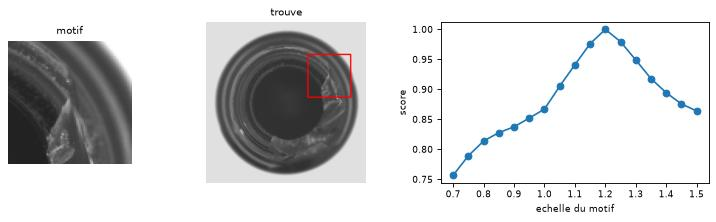

In [34]:
# bouteille saine en gris, reduite a 300 x 300
good_small = cv2.resize(cv2.cvtColor(read_image(BOTTLE_GOOD), cv2.COLOR_BGR2GRAY), (300, 300), interpolation=cv2.INTER_AREA)
template = small_bottle[60:140, 190:270]  # un morceau distinctif (bord casse)
scene = cv2.resize(small_bottle, None, fx=1.2, fy=1.2, interpolation=cv2.INTER_LINEAR)  # scene agrandie 1,2 fois
scene = np.clip(scene.astype(np.float32) * 0.8 + 20, 0, 255).astype(np.uint8)  # autre gain et decalage
scores = []  # (score, echelle, position, taille) pour chaque echelle essayee
for s in np.linspace(0.7, 1.5, 17):  # 17 echelles de 0,7 a 1,5 (pas de 0,05)
    t = cv2.resize(template, None, fx=s, fy=s, interpolation=cv2.INTER_LINEAR)  # motif mis a l'echelle s
    # cv2.matchTemplate(scene, motif, methode) : carte de score pour chaque position du motif
    res = cv2.matchTemplate(scene, t, cv2.TM_CCOEFF_NORMED)
    _, score, _, loc = cv2.minMaxLoc(res)  # cv2.minMaxLoc : (min, max, position du min, position du max) ; on garde le max
    scores.append((score, s, loc, t.shape))  # memorise le resultat
score, s, (x, y), (th, tw) = max(scores)  # meilleur score (max compare d'abord le premier element du tuple)
found = cv2.cvtColor(scene, cv2.COLOR_GRAY2BGR)  # copie couleur pour dessiner
cv2.rectangle(found, (x, y), (x + tw, y + th), (0, 0, 255), 2)  # boite trouvee en rouge
print(f"meilleur score {score:.3f} a l'echelle {s:.2f} (attendu 1,20), position x={x}, y={y}")  # resultat
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), gridspec_kw={"width_ratios": [0.6, 1, 1.3]})  # 3 cases de largeurs differentes
axes[0].imshow(template, cmap="gray", vmin=0, vmax=255)  # le motif
axes[0].set_title("motif")  # titre de la case
axes[1].imshow(cv2.cvtColor(found, cv2.COLOR_BGR2RGB))  # la scene avec la boite, convertie en RGB
axes[1].set_title("trouve")  # titre de la case
axes[0].axis("off")  # pas d'axes gradues
axes[1].axis("off")  # pas d'axes gradues
axes[2].plot([v[1] for v in scores], [v[0] for v in scores], "o-")  # courbe score selon l'echelle
axes[2].set_xlabel("echelle du motif")  # nom de l'axe horizontal
axes[2].set_ylabel("score")  # nom de l'axe vertical
plt.tight_layout()  # resserre les marges
plt.show()  # affiche la figure

### Points d'interet ORB + homographie (RANSAC)
ORB (rapide, libre) detecte des points d'interet et leurs descripteurs binaires ; on les apparie
(`BFMatcher`, distance de Hamming, `crossCheck`), puis `findHomography(RANSAC)` estime la
transformation en rejetant les mauvaises paires. Invariant a la rotation et a l'echelle : pour recaler
une image sur une reference avant de les comparer. Piege : sur une texture tres repetitive (acier
uniforme), les paires sont ambigues ; il faut des details distinctifs (bords, reperes, marquages).

101 / 67 points, 28 paires, 22 gardees par RANSAC


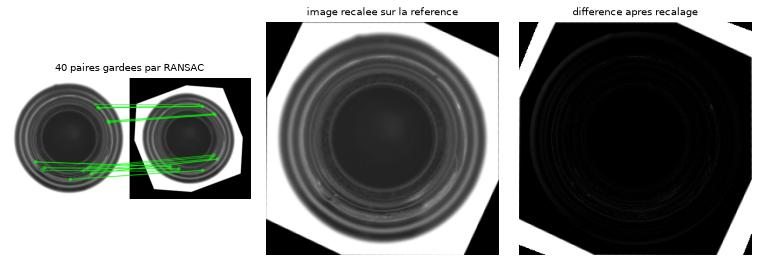

In [35]:
ref = good_small  # image de reference : la bouteille saine
hmat = cv2.getPerspectiveTransform(  # perspective simulee : 4 coins -> 4 points deplaces
    np.float32([[0, 0], [299, 0], [299, 299], [0, 299]]),  # les 4 coins de l'image 300 x 300
    np.float32([[20, 10], [285, 30], [270, 290], [5, 270]]),  # leurs positions apres deplacement
)
# image deplacee : rotation 25 degres + echelle 0,95, puis perspective
moved = cv2.warpPerspective(cv2.warpAffine(ref, cv2.getRotationMatrix2D((150, 150), 25, 0.95), (300, 300)), hmat, (300, 300))
orb = cv2.ORB_create(nfeatures=1500)  # cv2.ORB_create : detecteur de points d'interet ORB, au plus 1500 points
kp1, des1 = orb.detectAndCompute(ref, None)  # points (kp) et descripteurs binaires (des) de la reference ; None = pas de masque
kp2, des2 = orb.detectAndCompute(moved, None)  # idem sur l'image deplacee
# BFMatcher : appariement force brute, distance de Hamming ; crossCheck : paires reciproques ; tri par distance
matches = sorted(cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(des1, des2), key=lambda m: m.distance)
pts_ref = np.float32([kp1[m.queryIdx].pt for m in matches])  # coordonnees (x, y) des points apparies dans la reference
pts_mov = np.float32([kp2[m.trainIdx].pt for m in matches])  # et dans l'image deplacee
# cv2.findHomography(depart, arrivee, RANSAC, 3 px) : matrice 3 x 3 ; inliers = paires gardees
homography, inliers = cv2.findHomography(pts_mov, pts_ref, cv2.RANSAC, 3.0)
realigned = cv2.warpPerspective(moved, homography, (300, 300))  # applique l'homographie : l'image deplacee revient sur la reference
inlier_matches = [m for m, ok in zip(matches, inliers.ravel()) if ok][:40]  # les 40 premieres paires jugees bonnes par RANSAC
print(f"{len(kp1)} / {len(kp2)} points, {len(matches)} paires, {int(inliers.sum())} gardees par RANSAC")  # bilan
match_view = cv2.drawMatches(  # cv2.drawMatches : les deux vues cote a cote, paires reliees par un trait
    ref,  # premiere image
    kp1,  # ses points d'interet
    moved,  # seconde image
    kp2,  # ses points d'interet
    inlier_matches,  # paires a tracer
    None,  # pas d'image de sortie fournie : elle est creee
    matchColor=(0, 255, 0),  # traits en vert
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,  # ne dessine pas les points sans paire
)
# zone couverte par l'image recalee (le reste est du vide)
valid = cv2.warpPerspective(np.full_like(moved, 255), homography, (300, 300)) > 0
residual = np.where(valid, cv2.absdiff(ref, realigned), 0)  # cv2.absdiff : |reference - recalee|, seulement dans la zone valide
grid(  # trois images
    [match_view, realigned, residual],  # images
    ["40 paires gardees par RANSAC", "image recalee sur la reference", "difference apres recalage"],  # titres
    ncols=3,  # 3 images sur une ligne
    size=3.2,  # taille d'une case en pouces
)

### ECC : alignement fin sub-pixel
`findTransformECC` maximise la correlation entre deux images proches (decalage de quelques pixels,
petite rotation) : precision sub-pixel, sans points d'interet, donc aussi sur des textures. Modeles :
`MOTION_TRANSLATION`, `MOTION_EUCLIDEAN` (+ rotation), `MOTION_AFFINE`, `MOTION_HOMOGRAPHY`. A
utiliser apres un recalage grossier (ORB) ou quand la piece est deja presque en place.

correlation 0.9873
matrice appliquee : [[1.0, 0.026, 0.817], [-0.026, 1.0, 0.452]]
matrice estimee   : [[1.0, 0.026, 0.822], [-0.026, 1.0, 0.444]]
difference moyenne : avant 5.8, apres 2.0


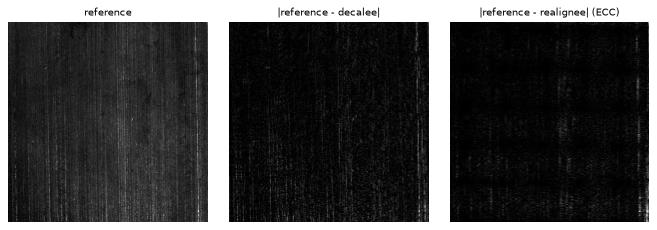

In [36]:
reference = read_image(TILE_FREE, 0)[20:220, 10:210].astype(np.float32)  # morceau 200 x 200 d'une tuile saine, en float32 (exige par ECC)
true_shift = cv2.getRotationMatrix2D((100, 100), 1.5, 1.0)  # rotation de 1,5 degre autour du centre
true_shift[:, 2] += (3.4, -2.2)  # plus un decalage de 3,4 px en x et -2,2 px en y (sub-pixel)
shifted = cv2.warpAffine(reference, true_shift, (200, 200), borderMode=cv2.BORDER_REFLECT)  # image deplacee, bords remplis en miroir
warp = np.eye(2, 3, dtype=np.float32)  # estimation de depart : matrice identite 2 x 3 (aucun deplacement)
criteria = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 100, 1e-6)  # arret apres 100 iterations ou quand l'amelioration < 1e-6
# cv2.findTransformECC(ref, image, depart, rotation + translation, arret, masque None, flou 5) ; cc = correlation
cc, warp = cv2.findTransformECC(reference, shifted, warp, cv2.MOTION_EUCLIDEAN, criteria, None, 5)
# WARP_INVERSE_MAP : applique la matrice dans le sens image -> reference, pour realigner
aligned = cv2.warpAffine(shifted, warp, (200, 200), flags=cv2.INTER_LINEAR + cv2.WARP_INVERSE_MAP, borderMode=cv2.BORDER_REFLECT)
print(f"correlation {cc:.4f}")  # correlation obtenue (1 = parfait)
print("matrice appliquee :", true_shift.round(3).tolist())  # matrice reelle
print("matrice estimee   :", np.round(warp.astype(float), 3).tolist())  # matrice trouvee : doit etre tres proche
inner = (slice(10, -10), slice(10, -10))  # zone interieure (10 px de marge) : ignore les bords remplis
# ecart moyen avant / apres alignement
print(f"difference moyenne : avant {np.abs(reference - shifted)[inner].mean():.1f}, apres {np.abs(reference - aligned)[inner].mean():.1f}")
grid(  # trois images
    [reference, np.abs(reference - shifted), np.abs(reference - aligned)],  # images
    ["reference", "|reference - decalee|", "|reference - realignee| (ECC)"],  # titres
    ncols=3,  # 3 images sur une ligne
    size=2.8,  # taille d'une case en pouces
)

### Comparaison a une reference ("golden template")
Pour des pieces repetables et bien positionnees : aligner l'image sur une reference saine, puis
calculer l'ecart. Une seule reference donne beaucoup de fausses alarmes (variations normales) ; on
moyenne plutot plusieurs pieces saines et on normalise l'ecart par leur ecart-type pixel par pixel
(z-score) : un pixel n'est suspect que s'il sort de la variabilite normale. Le seuil se regle sur
d'AUTRES pieces saines (ici 15, jamais vues) : le z-score maximal qu'elles atteignent. C'est
l'ancetre de PaDiM (meme idee, sur des descripteurs de reseau au lieu des niveaux de gris).

seuil = plus haut z-score (percentile 99,9) de 15 pieces saines non utilisees : 2.23
broken_large/000   pixels du defaut retrouves 10%, faux pixels 12
contamination/000  pixels du defaut retrouves 52%, faux pixels 121


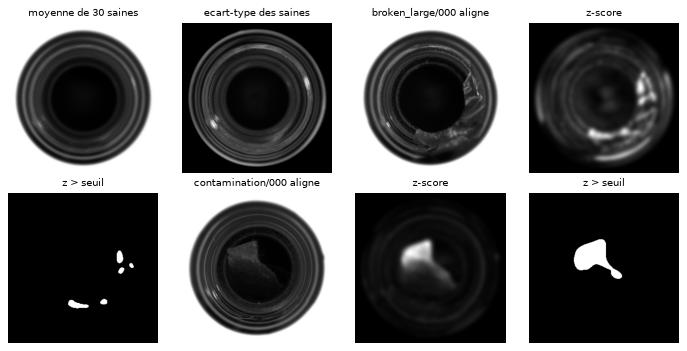

In [37]:
def load_small(path):  # lit une bouteille, la passe en gris, 300 x 300, float32 ; renvoie l'image
    # lecture BGR -> gris -> reduction INTER_AREA -> float32
    return cv2.resize(cv2.cvtColor(read_image(path), cv2.COLOR_BGR2GRAY), (300, 300), interpolation=cv2.INTER_AREA).astype(np.float32)


good_paths = sorted((DATA / "mvtec_bottle/train/good").glob("*.png"))  # toutes les bouteilles saines d'entrainement, triees
goods = np.stack([load_small(p) for p in good_paths[:30]])  # les 30 premieres empilees : forme (30, 300, 300) ; ce sont les references
mean_ref, std_ref = goods.mean(axis=0), goods.std(axis=0)  # moyenne et ecart-type de chaque pixel sur les 30 saines


def zscore_map(image, eps=4.0, sigma=4.0):  # carte des ecarts en ecarts-types ; renvoie (carte lissee, image alignee)
    """Ecart a la moyenne des saines, en nombre d'ecarts-types, apres alignement ECC sur la moyenne."""
    warp = np.eye(2, 3, dtype=np.float32)  # depart : identite
    # aligne l'image sur la moyenne des saines (ECC)
    _, warp = cv2.findTransformECC(mean_ref, image, warp, cv2.MOTION_EUCLIDEAN, criteria, None, 5)
    # image realignee
    aligned = cv2.warpAffine(image, warp, (300, 300), flags=cv2.INTER_LINEAR + cv2.WARP_INVERSE_MAP, borderMode=cv2.BORDER_REFLECT)
    # |ecart| / (ecart-type + eps, evite / 0 la ou les saines ne varient pas), lisse par un flou sigma 4
    return cv2.GaussianBlur(np.abs(aligned - mean_ref) / (std_ref + eps), (0, 0), sigma), aligned


# seuil = plus haut percentile 99,9 du z-score sur 15 saines jamais vues (images 30 a 44)
threshold = max(np.percentile(zscore_map(load_small(p))[0], 99.9) for p in good_paths[30:45])
print(f"seuil = plus haut z-score (percentile 99,9) de 15 pieces saines non utilisees : {threshold:.2f}")  # seuil retenu
k7 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))  # element structurant disque 7 x 7
# images et titres : d'abord la moyenne et l'ecart-type des saines
views, titles = [mean_ref, std_ref], ["moyenne de 30 saines", "ecart-type des saines"]
for name in ("broken_large/000", "contamination/000"):  # pour deux pieces defectueuses
    z, aligned = zscore_map(load_small(DATA / f"mvtec_bottle/test/{name}.png"))  # z-score de la piece
    # pixels au-dessus du seuil, nettoyes par ouverture puis fermeture 7 x 7 ; > 0 donne un booleen
    found = cv2.morphologyEx(cv2.morphologyEx((z > threshold).astype(np.uint8) * 255, cv2.MORPH_OPEN, k7), cv2.MORPH_CLOSE, k7) > 0
    truth = (  # masque de verite terrain
        # lu en gris, reduit a 300 x 300 en NEAREST (masque), binarise
        cv2.resize(read_image(DATA / f"mvtec_bottle/ground_truth/{name}_mask.png", 0), (300, 300), interpolation=cv2.INTER_NEAREST) > 127
    )
    print(  # part des pixels du defaut retrouves, et pixels signales a tort
        f"{name:18s} pixels du defaut retrouves {np.logical_and(found, truth).sum() / truth.sum():.0%}, faux pixels {np.logical_and(found, ~truth).sum()}"
    )
    views += [aligned, z, found]  # ajoute image alignee, z-score, detection
    titles += [f"{name} aligne", "z-score", "z > seuil"]  # et leurs titres
grid(views, titles, ncols=4, size=2.2)  # affichage

## 16. Segmentation classique
- **watershed** (ligne de partage des eaux) : separer des objets qui se touchent (grains, pastilles,
  bulles). Marqueurs = sommets de la transformee de distance, puis `cv2.watershed` trace les
  frontieres (valeur -1) ;
- **grabCut** : a partir d'une boite, separe objet et fond par modeles de couleur et graphe. Une
  boite d'annotation devient un masque : pre-annotation de segmentation a partir d'un jeu de
  detection (a relire) ;
- **inpainting** (`cv2.inpaint`) : reconstruire une zone masquee a partir de ses bords (reflet
  connu, logo, pixel mort). Jamais pour "nettoyer" une zone ou un defaut pourrait etre.

composantes connexes : 3 ; objets apres watershed : 6


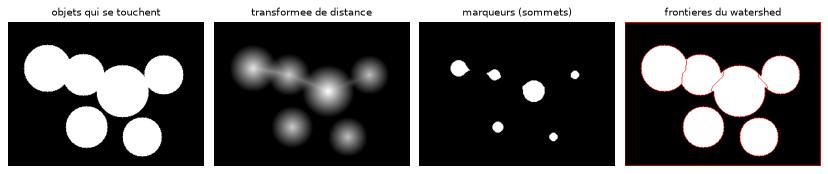

In [38]:
blobs = np.zeros((220, 300), np.uint8)  # image noire 220 x 300
# pour 6 disques (centre x, centre y, rayon)
for x, y, r in [(60, 70, 36), (115, 80, 32), (175, 105, 40), (238, 80, 30), (120, 160, 32), (205, 175, 30)]:
    cv2.circle(blobs, (x, y), r, 255, -1)  # disque blanc plein ; les disques se touchent
# cv2.distanceTransform(binaire, distance euclidienne, masque 5) : distance de chaque pixel blanc au noir
distance = cv2.distanceTransform(blobs, cv2.DIST_L2, 5)
_, peaks = cv2.threshold(distance, 0.6 * distance.max(), 255, cv2.THRESH_BINARY)  # sommets : pixels a plus de 60 % de la distance max
peaks = peaks.astype(np.uint8)  # en uint8 (connectedComponents l'exige)
n_markers, markers = cv2.connectedComponents(peaks)  # un numero par sommet (0 = le reste)
markers = markers + 1  # 1 = fond sur
markers[(cv2.dilate(blobs, k5) > 0) & (peaks == 0)] = 0  # 0 = inconnu, a attribuer par watershed
# cv2.watershed(image couleur, marqueurs) : attribue les zones inconnues ; frontieres = -1
markers = cv2.watershed(cv2.cvtColor(blobs, cv2.COLOR_GRAY2BGR), markers)
separated = cv2.cvtColor(blobs, cv2.COLOR_GRAY2BGR)  # copie couleur pour dessiner
separated[markers == -1] = (0, 0, 255)  # frontieres en rouge
# nombre d'objets avant / apres separation
print(f"composantes connexes : {cv2.connectedComponents(blobs)[0] - 1} ; objets apres watershed : {len(np.unique(markers)) - 2}")
grid(  # quatre images
    [blobs, distance, peaks, separated],  # images
    ["objets qui se touchent", "transformee de distance", "marqueurs (sommets)", "frontieres du watershed"],  # titres
    ncols=4,  # 4 images par ligne
)

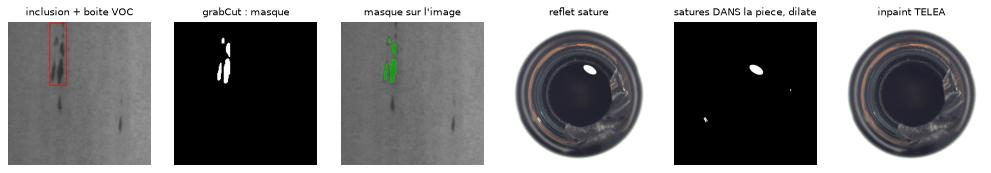

In [39]:
det = read_image(DET_IMAGE)  # NEU-DET : gris stocke en 3 canaux
boxes = []  # boites [xmin, ymin, xmax, ymax] lues dans le XML
for obj in ET.parse(DET_XML).getroot().iter("object"):  # pour chaque balise <object> du fichier VOC
    bb = obj.find("bndbox")  # sa balise <bndbox> (la boite)
    boxes.append([int(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax")])  # lit les 4 coordonnees en entiers
x0, y0, x1, y1 = max(boxes, key=lambda b: (b[2] - b[0]) * (b[3] - b[1]))  # la plus grande boite
gc_mask = np.zeros(det.shape[:2], np.uint8)  # masque de travail de grabCut, de la taille de l'image
# modeles internes du fond et de l'objet (tableaux 1 x 65 exiges par OpenCV)
bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
# cv2.grabCut(image, masque, boite (x, y, largeur, hauteur), modeles, 5 iterations, depart par la boite)
cv2.grabCut(det, gc_mask, (x0, y0, x1 - x0, y1 - y0), bgd, fgd, 5, cv2.GC_INIT_WITH_RECT)
# pixels classes objet sur (GC_FGD) ou probable (GC_PR_FGD), en 0 / 255
object_mask = np.isin(gc_mask, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8) * 255
box_view = det.copy()  # copie pour dessiner la boite
cv2.rectangle(box_view, (x0, y0), (x1, y1), (0, 0, 255), 1)  # la boite en rouge
overlay = det.copy()  # copie pour la superposition
# pixels de l'objet : moitie image + teinte verte
overlay[object_mask > 0] = (0.5 * overlay[object_mask > 0] + (0, 127, 0)).astype(np.uint8)

glare = bottle.copy()  # copie de la bouteille pour y ajouter un reflet
# cv2.ellipse(image, centre, demi-axes, angle, debut, fin, couleur, -1 = plein) : reflet sature simule
cv2.ellipse(glare, (520, 300), (45, 22), 30, 0, 360, (255, 255, 255), -1)
piece = cv2.circle(  # masque de la piece : disque blanc dessine dans une image noire
    np.zeros(glare.shape[:2], np.uint8),  # image noire de la taille de la photo
    (450, 450),  # centre (x, y)
    400,  # rayon en pixels
    255,  # couleur : blanc
    -1,  # epaisseur -1 = disque plein
)  # la piece (cercle de Hough x 3) : le fond blanc n'est pas un reflet
# pixels presque blancs (>= 250) DANS la piece, dilates par k5 pour couvrir le bord du reflet
glare_mask = cv2.dilate(((cv2.cvtColor(glare, cv2.COLOR_BGR2GRAY) >= 250) & (piece > 0)).astype(np.uint8) * 255, k5)
# cv2.inpaint(image, masque, rayon 5, methode TELEA) : reconstruit la zone a partir de ses bords
telea = cv2.inpaint(glare, glare_mask, 5, cv2.INPAINT_TELEA)
grid(  # six images
    [box_view, object_mask, overlay, glare, glare_mask, telea],  # images
    # titres
    ["inclusion + boite VOC", "grabCut : masque", "masque sur l'image", "reflet sature", "satures DANS la piece, dilate", "inpaint TELEA"],
    ncols=6,  # 6 images sur une ligne
    size=2.1,  # taille d'une case en pouces
)

## 17. Tuiles et dessin d'annotations
### Decouper une grande image en tuiles avec recouvrement, puis reassembler
Une bande de 4096 pixels ne passe pas dans un reseau a 512 : on la decoupe en tuiles qui se
recouvrent (un defaut coupe au bord d'une tuile est entier dans la voisine), on traite chaque tuile,
on reassemble (moyenne dans les recouvrements pour une image ou une carte ; boites decalees de
l'origine de la tuile puis fusion par NMS pour une detection). La derniere tuile est collee au bord
pour tout couvrir sans remplissage.

25 tuiles de 256 px ; reassemblage sans traitement : ecart max 0.0


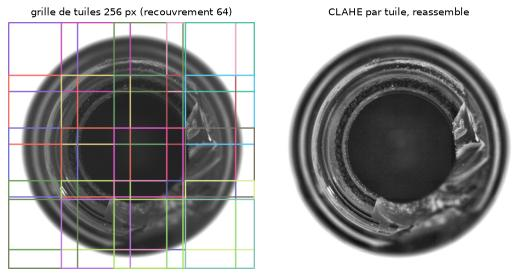

In [40]:
def tile_starts(length, size, overlap):  # positions de depart des tuiles le long d'un cote ; renvoie une liste d'entiers
    step = size - overlap  # pas entre deux tuiles = taille - recouvrement
    starts = list(range(0, max(length - size, 0) + 1, step))  # departs reguliers tant que la tuile tient dans l'image
    if starts[-1] + size < length:  # si la fin n'est pas couverte
        starts.append(length - size)  # derniere tuile collee au bord
    return starts  # liste des departs


def split_tiles(image, size=256, overlap=64):  # decoupe en tuiles ; renvoie une liste de ((y, x), tuile)
    h, w = image.shape[:2]  # hauteur et largeur
    # chaque tuile : sa position et une vue de l'image (pas de copie)
    return [((y, x), image[y : y + size, x : x + size]) for y in tile_starts(h, size, overlap) for x in tile_starts(w, size, overlap)]


def merge_tiles(tiles, shape):  # reassemble ; renvoie une image float32 de taille shape
    """Reassemble des tuiles (traitees) en moyennant les recouvrements."""
    total = np.zeros(shape, np.float32)  # somme des valeurs recues par chaque pixel
    count = np.zeros(shape[:2], np.float32)  # nombre de tuiles qui couvrent chaque pixel
    for (y, x), t in tiles:  # pour chaque tuile et sa position
        total[y : y + t.shape[0], x : x + t.shape[1]] += t  # ajoute la tuile a sa place
        count[y : y + t.shape[0], x : x + t.shape[1]] += 1  # une couverture de plus
    return total / np.maximum(count, 1)  # moyenne (max(..., 1) evite / 0)


large = bottle_g  # 900 x 900
tiles = split_tiles(large, 256, 64)  # tuiles de 256 px, recouvrement 64
identity = merge_tiles(tiles, large.shape)  # reassemblage sans traitement : doit redonner l'image
# nombre de tuiles et ecart max (doit valoir 0)
print(f"{len(tiles)} tuiles de 256 px ; reassemblage sans traitement : ecart max {np.abs(identity - large).max():.1f}")
# CLAHE (limite 2, grille 4 x 4) sur chaque tuile, puis reassemblage
processed = merge_tiles([(pos, cv2.createCLAHE(2.0, (4, 4)).apply(t)) for pos, t in tiles], large.shape)
tiles_view = cv2.cvtColor(large, cv2.COLOR_GRAY2BGR)  # copie couleur pour dessiner la grille
for (y, x), t in tiles:  # pour chaque tuile
    # son cadre (retreci de 2 px), couleur au hasard, epaisseur 3
    cv2.rectangle(tiles_view, (x + 2, y + 2), (x + t.shape[1] - 3, y + t.shape[0] - 3), tuple(int(v) for v in rng.integers(80, 255, 3)), 3)
grid(  # deux images
    [tiles_view, processed.astype(np.uint8)],  # images (float -> uint8)
    ["grille de tuiles 256 px (recouvrement 64)", "CLAHE par tuile, reassemble"],  # titres
    ncols=2,  # 2 images sur une ligne
    size=3.4,  # taille d'une case en pouces
)

### Dessiner des annotations lisibles
Boites (`rectangle`), etiquettes sur fond plein (`getTextSize` pour la taille du texte), polygones
(`polylines`, `fillPoly`) en transparence (`addWeighted`), fleche, barre d'echelle en mm. Toujours
dessiner sur une COPIE (les fonctions de dessin modifient l'image en place) et en couleur (BGR).

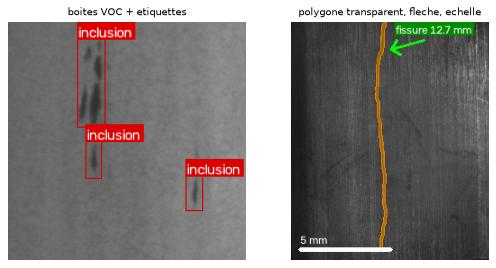

In [41]:
# ecrit un texte blanc sur un fond de couleur, dans l'image elle-meme ; ne renvoie rien
def draw_label(image, text, x, y, color, scale=0.4):
    # cv2.getTextSize(texte, police, echelle, epaisseur) : (largeur, hauteur) et ligne de base
    (tw, th), base = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, 1)
    y = max(y, th + base + 2)  # garde l'etiquette dans l'image (pas au-dessus du bord)
    cv2.rectangle(image, (x, y - th - base - 2), (x + tw + 2, y), color, -1)  # fond plein (-1) de la couleur donnee
    # cv2.putText(image, texte, coin bas-gauche, police, echelle, blanc, epaisseur 1, LINE_AA = trait lisse)
    cv2.putText(image, text, (x + 1, y - base), cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), 1, cv2.LINE_AA)


annotated = det.copy()  # copie a annoter
for x0, y0, x1, y1 in boxes:  # pour chaque boite VOC
    cv2.rectangle(annotated, (x0, y0), (x1, y1), (0, 0, 220), 1)  # la boite
    draw_label(annotated, "inclusion", x0, y0, (0, 0, 220))  # son etiquette au-dessus

tile_view = cv2.cvtColor(tile, cv2.COLOR_GRAY2BGR)  # tuile fissuree en couleur
contours, _ = cv2.findContours(crack_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  # contours de la fissure (masque de verite)
layer = tile_view.copy()  # calque a remplir
cv2.fillPoly(layer, contours, (0, 200, 255))  # cv2.fillPoly : remplit les contours en orange
tile_view = cv2.addWeighted(layer, 0.45, tile_view, 0.55, 0)  # remplissage transparent
cv2.polylines(tile_view, contours, True, (0, 120, 255), 1)  # trait du contour, ferme
# cv2.boundingRect : boite droite (x, y, largeur, hauteur) du plus grand contour
x, y, bw, bh = cv2.boundingRect(max(contours, key=cv2.contourArea))
# cv2.arrowedLine(image, depart, pointe, couleur, epaisseur, pointe = 30 % de la longueur) : fleche
cv2.arrowedLine(tile_view, (x + bw + 40, y + 20), (x + bw + 4, y + 30), (0, 255, 0), 2, tipLength=0.3)
draw_label(tile_view, f"fissure {bh * MM_PER_PX:.1f} mm", x + bw + 8, y + 12, (0, 140, 0))  # longueur estimee par la hauteur de la boite
bar_px = int(round(5 / MM_PER_PX))  # barre d'echelle de 5 mm
h_t = tile_view.shape[0]  # hauteur de l'image
cv2.line(tile_view, (10, h_t - 12), (10 + bar_px, h_t - 12), (255, 255, 255), 3)  # barre blanche en bas a gauche
cv2.putText(tile_view, "5 mm", (10, h_t - 18), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1, cv2.LINE_AA)  # legende de la barre
grid([annotated, tile_view], ["boites VOC + etiquettes", "polygone transparent, fleche, echelle"], ncols=2, size=3.4)  # resultat

## 18. Aide-memoire

| besoin | fonction OpenCV | parametres types | remarque |
|---|---|---|---|
| lire (accents, 16 bits) | `cv2.imdecode(np.fromfile(p, np.uint8), cv2.IMREAD_UNCHANGED)` | | tester `None` |
| ecrire | `cv2.imencode(".png", img)[1].tofile(p)` | JPEG : `[cv2.IMWRITE_JPEG_QUALITY, 95]` | PNG = sans perte |
| 16 -> 8 bits | `np.clip((img - lo) * 255 / (hi - lo), 0, 255)` | lo, hi fixes | jamais `>> 8` aveugle |
| couleur | `cv2.cvtColor(img, cv2.COLOR_BGR2GRAY / BGR2RGB / BGR2HSV / BGR2LAB)` | | H dans 0-179 |
| redimensionner | `cv2.resize(img, (w, h), interpolation=...)` | AREA (reduire), LINEAR/CUBIC (agrandir), NEAREST (masques) | (w, h) ! |
| letterbox | `resize` + `cv2.copyMakeBorder(..., BORDER_CONSTANT, value=114)` | | garder ratio, dx, dy |
| rotation | `cv2.getRotationMatrix2D(c, a, s)` + `cv2.warpAffine` | `borderMode=BORDER_REFLECT` | `cv2.rotate` pour 90 |
| perspective | `cv2.getPerspectiveTransform(src4, dst4)` + `cv2.warpPerspective` | | avant toute mesure |
| polaire | `cv2.warpPolar(img, (r, 720), centre, r, WARP_POLAR_LINEAR)` | | centre precis |
| contraste | `cv2.createCLAHE(clipLimit=2, tileGridSize=(8, 8)).apply(gray)` | clip 1-4 | sur L pour la couleur |
| gamma | `cv2.LUT(img, table)` | gamma 0,5-2 | table de 256 |
| shading | `img / cv2.GaussianBlur(img, (0, 0), sigma) * moyenne` | sigma = 3-5 x defaut | float32 |
| details sombres / clairs | `cv2.morphologyEx(img, MORPH_BLACKHAT / MORPH_TOPHAT, k)` | k > defaut | |
| camera lineaire | `img / np.median(img, axis=0)` | | sur beaucoup de lignes |
| debruiter | `GaussianBlur`, `medianBlur(img, 5)`, `bilateralFilter(img, 7, 40, 5)`, `fastNlMeansDenoising(img, None, 15)` | | verifier les petits defauts |
| nettete | `cv2.Laplacian(img, CV_64F).var()` | | seuil sur images nettes |
| seuil | `cv2.threshold(img, 0, 255, THRESH_BINARY + THRESH_OTSU)`, `cv2.adaptiveThreshold(img, 255, ADAPTIVE_THRESH_GAUSSIAN_C, THRESH_BINARY, 51, C)` | blockSize impair | apres shading |
| morphologie | `cv2.morphologyEx(b, MORPH_OPEN / CLOSE / GRADIENT, k)` | `getStructuringElement(MORPH_ELLIPSE, (5, 5))` | |
| objets | `cv2.connectedComponentsWithStats(b, connectivity=8)` | | aire = pixels |
| contours | `cv2.findContours(b, RETR_EXTERNAL, CHAIN_APPROX_SIMPLE)` | `minAreaRect`, `fitEllipse`, `convexHull`, `moments` | |
| bords | `cv2.Sobel(img, CV_32F, 1, 0)`, `cv2.Canny(img, lo, hi)` | lo/hi par percentiles | sortie float |
| lignes, cercles | `cv2.HoughLinesP(edges, 1, pi/180, 40, minLineLength=40, maxLineGap=6)`, `cv2.HoughCircles(...)` | rayons min/max | |
| spectre | `np.fft.fftshift(np.fft.fft2(img))` | `log1p(abs)` | trames = pics |
| texture | `cv2.getGaborKernel((31, 31), 4, theta, 10, 0.4)` + `cv2.filter2D` | banque d'angles | retirer la moyenne |
| motif | `cv2.matchTemplate(img, t, TM_CCOEFF_NORMED)` + `cv2.minMaxLoc` | plusieurs echelles | |
| recalage | `cv2.ORB_create` + `BFMatcher(NORM_HAMMING)` + `findHomography(RANSAC)` ; `findTransformECC` | | ECC = fin |
| objets colles | `cv2.distanceTransform` + `cv2.watershed` | | marqueurs |
| boite -> masque | `cv2.grabCut(img, mask, rect, ..., 5, GC_INIT_WITH_RECT)` | | a relire |
| effacer une zone | `cv2.inpaint(img, mask, 5, INPAINT_TELEA)` | | pas sur un defaut |
| dessiner | `rectangle`, `putText`, `getTextSize`, `polylines`, `fillPoly`, `addWeighted` | | sur une copie |

## 19. Une chaine complete : de l'image brute a la mesure en mm
Une inspection classique de tuile, enchainee et chronometree : division par le fond flou
(eclairage) -> CLAHE (contraste local) -> black-hat (ecart sombre au fond) -> seuil par hysteresis a
des niveaux FIXES -> morphologie -> filtre de forme (assez grand, ou long et fin) -> mesures en mm.

Les niveaux du seuil sont appris UNE fois sur des tuiles SAINES (percentiles 99 et 99,9 de leur
score), jamais par image : un seuil recalcule par image trouve toujours "quelque chose", meme sur une
tuile parfaite. Les 10 pixels du bord sont ignores (bord de la tuile, effets de bord des filtres).

niveaux fixes appris sur 30 tuiles saines : bas 91.1, haut 121.9

MT_Crack : 3 objet(s) ; 2.9 ms (shading 1.7, CLAHE 0.1, black-hat 0.5, hysteresis 0.3, morphologie 0.0, forme + mesures 0.2)
   fissure/rayure  longueur  1.45 mm, largeur 0.30 mm, 121 px = 0.30 mm2
   tache           longueur  0.65 mm, largeur 0.65 mm, 147 px = 0.37 mm2
   fissure/rayure  longueur  6.45 mm, largeur 0.46 mm, 484 px = 1.21 mm2

MT_Blowhole : 2 objet(s) ; 2.7 ms (shading 1.6, CLAHE 0.1, black-hat 0.5, hysteresis 0.2, morphologie 0.0, forme + mesures 0.1)
   trou/piqure     longueur  0.65 mm, largeur 0.45 mm, 109 px = 0.27 mm2
   tache           longueur  0.60 mm, largeur 0.35 mm, 86 px = 0.22 mm2

MT_Free : 9 objet(s) ; 3.5 ms (shading 1.8, CLAHE 0.2, black-hat 0.4, hysteresis 0.5, morphologie 0.0, forme + mesures 0.6)
   tache           longueur  0.87 mm, largeur 0.86 mm, 156 px = 0.39 mm2
   tache           longueur  2.05 mm, largeur 0.90 mm, 450 px = 1.13 mm2
   tache           longueur  3.50 mm, largeur

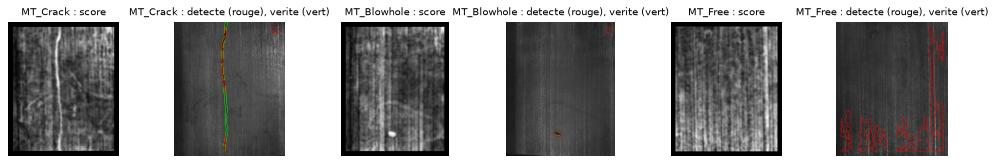

In [42]:
# chaine d'inspection complete d'une tuile ; renvoie (masque, mesures, temps par etape, score)
def inspect_tile(gray, low, high, min_area=50, min_length=25, margin=10, mm_per_px=MM_PER_PX):
    """Chaine classique sur une image grise ; renvoie (masque, mesures, temps par etape en ms, score)."""
    timings, t0 = {}, time.perf_counter()  # temps par etape (ms) et heure de debut d'etape

    def lap(name):  # fonction interne : note la duree de l'etape name et relance le chrono
        nonlocal t0  # nonlocal : on modifie la variable t0 de la fonction englobante
        now = time.perf_counter()  # heure actuelle
        timings[name] = (now - t0) * 1000  # duree de l'etape en millisecondes
        t0 = now  # debut de l'etape suivante

    g = gray.astype(np.float32)  # float32
    # shading : divise par le fond flou (sigma 20), ramene autour de 128, retour en uint8
    g = np.clip(g / np.maximum(cv2.GaussianBlur(g, (0, 0), 20), 1) * 128, 0, 255).astype(np.uint8)
    lap("shading")  # fin de l'etape shading
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(2, 2)).apply(g)  # CLAHE limite 2, grille 2 x 2
    lap("CLAHE")  # fin de l'etape CLAHE
    # black-hat 15 x 15 : details sombres (fissures, trous) = score de defaut
    score = cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)))
    score = cv2.GaussianBlur(score.astype(np.float32), (0, 0), 1.5)  # lisse les stries d'un pixel
    # met a 0 les 10 pixels de chaque bord (haut, bas, gauche, droite)
    score[:margin], score[-margin:], score[:, :margin], score[:, -margin:] = 0, 0, 0, 0
    lap("black-hat")  # fin de l'etape black-hat
    mask = hysteresis(score, low, high)  # seuil par hysteresis aux niveaux fixes
    lap("hysteresis")  # fin de l'etape hysteresis
    # fermeture 3 x 3 : recolle les morceaux proches
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
    lap("morphologie")  # fin de l'etape morphologie
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  # contours des objets detectes
    kept, measures = [], []  # contours gardes et leurs mesures
    for c in contours:  # pour chaque objet
        (_, _), (rw, rh), _ = cv2.minAreaRect(c)  # taille du rectangle oriente (le reste est ignore avec _)
        length, width = max(rw, rh), max(min(rw, rh), 1.0)  # grand cote et petit cote (au moins 1)
        if cv2.contourArea(c) >= min_area or (length >= min_length and length / width >= 4):  # assez grand, OU long et fin (fissure)
            kept.append(c)  # on le garde
            # nombre exact de pixels : contour rempli dans une image vide, puis compte
            pixels = int(cv2.countNonZero(cv2.drawContours(np.zeros_like(mask), [c], -1, 255, -1)))
            # mesures de forme + nombre de pixels (| fusionne deux dictionnaires)
            measures.append(measure(c, mm_per_px) | {"pixels": pixels})
    mask = cv2.drawContours(np.zeros_like(mask), kept, -1, 255, -1)  # masque final : seulement les objets gardes, remplis
    lap("forme + mesures")  # fin de la derniere etape
    return mask, measures, timings, score  # masque, mesures, temps, score


free_paths = sorted((DATA / "magnetic_tile/MT_Free/Imgs").glob("*.jpg"))  # toutes les tuiles saines, triees
# scores de 30 tuiles saines (seuils 1e9 : seul le score [3] compte), mis bout a bout
calib_scores = np.concatenate([inspect_tile(read_image(p, 0), 1e9, 1e9)[3].ravel() for p in free_paths[:30]])
LOW, HIGH = (float(v) for v in np.percentile(calib_scores, (99.0, 99.9)))  # niveaux fixes = percentiles 99 et 99,9 des scores sains
print(f"niveaux fixes appris sur 30 tuiles saines : bas {LOW:.1f}, haut {HIGH:.1f}")  # niveaux retenus

views, titles = [], []  # images et titres a afficher
for path in (TILE_CRACK, TILE_HOLE, TILE_FREE):  # pour une fissure, un trou et une tuile saine
    gray = read_image(path, 0)  # lecture en gris
    mask, measures, timings, score = inspect_tile(gray, LOW, HIGH)  # la chaine complete
    truth = mask_of(path)  # verite terrain
    view = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)  # copie couleur pour dessiner
    # contours de la verite en vert
    cv2.drawContours(view, cv2.findContours(truth, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], -1, (0, 255, 0), 1)
    # contours detectes en rouge
    cv2.drawContours(view, cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], -1, (0, 0, 255), 1)
    name = path.parent.parent.name  # nom du dossier de classe (MT_Crack...)
    # nombre d'objets et temps total puis par etape
    print(f"\n{name} : {len(measures)} objet(s) ; {sum(timings.values()):.1f} ms ({', '.join(f'{k} {v:.1f}' for k, v in timings.items())})")
    for m in measures:  # pour chaque objet detecte
        print(  # type, dimensions et aire en mm2
            f"   {m['type']:15s} longueur {m['longueur_mm']:5.2f} mm, largeur {m['largeur_mm']:4.2f} mm, {m['pixels']} px = {m['pixels'] * MM_PER_PX**2:.2f} mm2"
        )
    views += [score, view]  # score et image annotee
    titles += [f"{name} : score", f"{name} : detecte (rouge), verite (vert)"]  # leurs titres
grid(views, titles, ncols=6, size=2.1)  # deux images par tuile

**Toujours mesurer sur un lot, jamais sur un bel exemple.** La meme chaine, sans rien changer, sur
20 fissures, 20 trous et 60 tuiles saines qui n'ont pas servi a regler les seuils :

In [43]:
def detected(path):  # vrai la ou la chaine detecte un defaut ; renvoie un masque booleen
    return inspect_tile(read_image(path, 0), LOW, HIGH)[0] > 0  # [0] = le masque ; > 0 donne des booleens


report = {}  # taux de defauts touches, par type
for label, folder, n in (("fissures", "MT_Crack", 20), ("trous", "MT_Blowhole", 20)):  # pour les fissures puis les trous (20 de chaque)
    paths = sorted((DATA / f"magnetic_tile/{folder}/Imgs").glob("*.jpg"))[:n]  # les n premieres images du dossier
    # part des images ou la detection touche au moins un pixel du vrai defaut
    report[label] = sum(bool(np.logical_and(detected(p), mask_of(p) > 0).any()) for p in paths) / len(paths)
false_alarms = np.mean([detected(p).any() for p in free_paths[30:90]])  # part des 60 tuiles saines jamais vues signalees a tort
# bilan sur le lot
print(f"defaut touche : fissures {report['fissures']:.0%}, trous {report['trous']:.0%} | tuiles saines signalees : {false_alarms:.0%}")

defaut touche : fissures 80%, trous 50% | tuiles saines signalees : 48%


Lecture : la chaine trouve la plupart des fissures et la moitie des trous, mais signale aussi pres
d'une tuile saine sur deux (comme la tuile saine ci-dessus : bord sombre et taches de texture). Monter les seuils reduit les fausses alarmes et fait rater des defauts :
sur une texture aussi variable, des regles fixes plafonnent. C'est exactement le cas ou l'on passe a
l'apprentissage (anomalies : notebooks 13-15, PatchCore atteint une AUROC image de 0,965 sur ce jeu ;
segmentation : notebook 12), en gardant ce pretraitement (shading, CLAHE) en entree s'il aide a la
metrique. Une chaine classique reste excellente quand l'eclairage et la piece sont maitrises :
mesure de cote, presence / absence, comptage, controle de position.

## Pour aller plus loin
- Choisir un pretraitement a la METRIQUE (un modele entraine dessus), pas a l'oeil : recette
  `recipes/preprocessing` et notebook 07.
- Les memes operations, nommees et enchainees par un YAML, appliquees a l'identique a l'entrainement,
  en prediction et a l'export : `vtb.preprocess` (49 operations).
- Quand une chaine classique ne suffit plus (textures variables, defauts sans contraste) : anomalies
  (notebooks 13-15) ou segmentation (12), avec ce pretraitement en entree.